from pathlib import Path
import subprocess

VOLUME = Path("/workspace")  # Use the mount path shown for b3it-results
assert VOLUME.is_mount(), f"No mounted volume found at {VOLUME}. Check the Volumes tab."

ROOT = VOLUME / "B3IT_Figure1_Gemma1B"
REPO_DIR = ROOT / "repo"
PROJECT_DIR = REPO_DIR / "track-llm-apis"
RESULTS_DIR = ROOT / "results"

ROOT.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

url = "https://github.com/timothee-chauvin/token-efficient-change-detection-llm-apis.git"
commit = "ad2f69295797a5f03e7b480246080d91087d9007"

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", url, str(REPO_DIR)], check=True)
    subprocess.run(["git", "checkout", "--detach", commit], cwd=REPO_DIR, check=True)

revision = subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=REPO_DIR, text=True
).strip()
assert revision == commit, f"Unexpected repository revision: {revision}"
assert (PROJECT_DIR / "uv.lock").is_file(), "Project dependency lockfile is missing."

print("Step 1 passed.")
print("Repository revision:", revision)
print("Project:", PROJECT_DIR)
print("Results folder:", RESULTS_DIR)

Step 2 is to install the repository’s locked dependencies and verify that PyTorch can use BF16 on your RTX A5000.

In [5]:
from pathlib import Path
import shutil
import subprocess
import sys

PROJECT_DIR = Path("/workspace/B3IT_Figure1_Gemma1B/repo/track-llm-apis")
PYTHON = str(PROJECT_DIR / ".venv/bin/python")

uv = shutil.which("uv")
if uv:
    uv_cmd = [uv]
else:
    subprocess.run([sys.executable, "-m", "pip", "install", "uv"], check=True)
    uv_cmd = [sys.executable, "-m", "uv"]

subprocess.run(
    [*uv_cmd, "sync", "--frozen", "--no-dev", "--python", "3.11"],
    cwd=PROJECT_DIR,
    check=True,
)

check = """
import torch
from importlib.metadata import version

print("PyTorch:", torch.__version__)
print("vLLM:", version("vllm"))
assert torch.cuda.is_available(), "PyTorch cannot see the GPU."
print("GPU:", torch.cuda.get_device_name(0))
assert torch.cuda.is_bf16_supported(including_emulation=False), "Native BF16 unavailable."

x = torch.ones((16, 16), device="cuda", dtype=torch.bfloat16)
assert (x @ x)[0, 0].item() == 16
print("Step 2 passed: native BF16 calculation succeeded.")
"""
subprocess.run([PYTHON, "-c", check], cwd=PROJECT_DIR, check=True)

Checked 214 packages in 333ms


PyTorch: 2.9.1+cu128
vLLM: 0.15.0
GPU: NVIDIA RTX A5000
Step 2 passed: native BF16 calculation succeeded.


CompletedProcess(args=['/workspace/B3IT_Figure1_Gemma1B/repo/track-llm-apis/.venv/bin/python', '-c', '\nimport torch\nfrom importlib.metadata import version\n\nprint("PyTorch:", torch.__version__)\nprint("vLLM:", version("vllm"))\nassert torch.cuda.is_available(), "PyTorch cannot see the GPU."\nprint("GPU:", torch.cuda.get_device_name(0))\nassert torch.cuda.is_bf16_supported(including_emulation=False), "Native BF16 unavailable."\n\nx = torch.ones((16, 16), device="cuda", dtype=torch.bfloat16)\nassert (x @ x)[0, 0].item() == 16\nprint("Step 2 passed: native BF16 calculation succeeded.")\n'], returncode=0)

In [3]:
from pathlib import Path
import os
import shutil
import subprocess

PROJECT_DIR = Path("/workspace/B3IT_Figure1_Gemma1B/repo/track-llm-apis")
LOCAL_ENV = Path("/opt/b3it-gemma-venv")
PYTHON = str(LOCAL_ENV / "bin/python")

env = os.environ.copy()
env["UV_PROJECT_ENVIRONMENT"] = str(LOCAL_ENV)
env["UV_LINK_MODE"] = "hardlink"
# Keep the cache on the container disk and reuse downloaded packages when available.
env["UV_CACHE_DIR"] = "/root/.cache/uv"

print(f"Free space on container disk: {shutil.disk_usage('/opt').free / 2**30:.1f} GiB",
      flush=True)

subprocess.run(
    ["/usr/bin/uv", "sync", "--frozen", "--no-dev", "--python", "3.11"],
    cwd=PROJECT_DIR,
    env=env,
    check=True,
)

check = """
import torch
from importlib.metadata import version

print("PyTorch:", torch.__version__)
print("vLLM:", version("vllm"))
assert torch.cuda.is_available(), "PyTorch cannot see the GPU."
print("GPU:", torch.cuda.get_device_name(0))
assert torch.cuda.is_bf16_supported(including_emulation=False), "Native BF16 unavailable."
x = torch.ones((16, 16), device="cuda", dtype=torch.bfloat16)
assert (x @ x)[0, 0].item() == 16
"""
subprocess.run([PYTHON, "-c", check], cwd=PROJECT_DIR, check=True)

partial_env = PROJECT_DIR / ".venv"
if (partial_env / "pyvenv.cfg").is_file():
    shutil.rmtree(partial_env)

print("Step 2 passed: local environment ready and native BF16 verified.")

Free space on container disk: 50.0 GiB


Using CPython 3.11.18 interpreter at: /usr/bin/python3.11
Creating virtual environment at: /opt/b3it-gemma-venv
Prepared 214 packages in 19.97s
Installed 214 packages in 571ms
 + accelerate==1.12.0
 + aiohappyeyeballs==2.6.1
 + aiohttp==3.13.3
 + aiosignal==1.4.0
 + annotated-doc==0.0.4
 + annotated-types==0.7.0
 + anthropic==0.77.1
 + anyio==4.12.1
 + apache-tvm-ffi==0.1.8.post2
 + astor==0.8.1
 + attrs==25.4.0
 + beartype==0.22.9
 + blake3==1.0.8
 + cachetools==7.0.0
 + cbor2==5.8.0
 + certifi==2026.1.4
 + cffi==2.0.0
 + charset-normalizer==3.4.4
 + choreographer==1.2.1
 + click==8.3.1
 + cloudpickle==3.1.2
 + compressed-tensors==0.13.0
 + contourpy==1.3.3
 + cryptography==46.0.4
 + cuda-bindings==13.1.1
 + cuda-pathfinder==1.3.3
 + cuda-python==13.1.1
 + cupy-cuda12x==13.6.0
 + cycler==0.12.1
 + datasets==4.5.0
 + deepspeed==0.18.5
 + depyf==0.20.0
 + diffusers==0.36.0
 + dill==0.4.0
 + diskcache==5.6.3
 + distro==1.9.0
 + dnspython==2.8.0
 + docstring-parser==0.17.0
 + einops==0.8.

PyTorch: 2.9.1+cu128
vLLM: 0.15.0
GPU: NVIDIA RTX A5000
Step 2 passed: local environment ready and native BF16 verified.


Step 3 — Verify Hugging Face access for Gemma and the LMSYS dataset.

In [4]:
import os
import subprocess
from getpass import getpass

if not os.environ.get("HF_TOKEN"):
    os.environ["HF_TOKEN"] = getpass("Hugging Face read token: ").strip()

check_access = """
from huggingface_hub import HfApi

api = HfApi(token=True)
api.auth_check(repo_id="google/gemma-3-1b-it", repo_type="model")
print("Gemma model access verified.", flush=True)

api.auth_check(repo_id="lmsys/lmsys-chat-1m", repo_type="dataset")
print("LMSYS dataset access verified.", flush=True)
"""

subprocess.run(
    ["/opt/b3it-gemma-venv/bin/python", "-c", check_access],
    check=True,
)
print("Step 3 passed.")

Hugging Face read token:  ········


Gemma model access verified.
LMSYS dataset access verified.
Step 3 passed.


Step 4 — Run Gemma once in BF16 on the RTX A5000.

In [7]:
import os
os.environ["HF_HUB_ENABLE_HF_TRANSFER"] = "0"
import subprocess
from pathlib import Path

# Keep downloaded model files on the container disk.
os.environ["HF_HUB_CACHE"] = "/opt/b3it-hf-cache"
os.environ["VLLM_WORKER_MULTIPROC_METHOD"] = "spawn"

results = Path("/workspace/B3IT_Figure1_Gemma1B/results")
results.mkdir(parents=True, exist_ok=True)

test_code = """
import json
import sys
from pathlib import Path
from vllm import LLM, SamplingParams

model = "google/gemma-3-1b-it"
llm = LLM(
    model=model,
    dtype="bfloat16",
    max_model_len=1024,
    max_num_seqs=64,
    gpu_memory_utilization=0.7,
    enforce_eager=True,
    enable_prefix_caching=False,
)

output = llm.generate(
    ["The capital of France is"],
    SamplingParams(temperature=0, max_tokens=1),
    use_tqdm=False,
)[0].outputs[0]

token_ids = list(output.token_ids)
assert len(token_ids) == 1, f"Expected one token, received {token_ids}"
record = {"model": model, "dtype": "bfloat16", "token_ids": token_ids, "text": output.text}
Path(sys.argv[1]).write_text(json.dumps(record, indent=2))
print("Generated token:", repr(output.text), "ID:", token_ids[0], flush=True)
"""

subprocess.run(
    ["/opt/b3it-gemma-venv/bin/python", "-c", test_code,
     str(results / "gemma_bf16_test.json")],
    check=True,
)
print("Step 4 passed: Gemma generated one token in BF16.")

INFO 11-11 20:33:30 [utils.py:261] non-default args: {'dtype': 'bfloat16', 'max_model_len': 1024, 'enable_prefix_caching': False, 'gpu_memory_utilization': 0.7, 'max_num_seqs': 64, 'disable_log_stats': True, 'enforce_eager': True, 'model': 'google/gemma-3-1b-it'}
INFO 11-11 20:33:44 [model.py:541] Resolved architecture: Gemma3ForCausalLM
INFO 11-11 20:33:44 [model.py:1561] Using max model len 1024
INFO 11-11 20:33:44 [scheduler.py:226] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 11-11 20:33:44 [vllm.py:624] Asynchronous scheduling is enabled.
WARNING 11-11 20:33:44 [vllm.py:662] Enforce eager set, overriding optimization level to -O0
INFO 11-11 20:33:44 [vllm.py:762] Cudagraph is disabled under eager mode
(EngineCore_DP0 pid=1730) INFO 11-11 20:33:57 [core.py:96] Initializing a V1 LLM engine (v0.15.0) with config: model='google/gemma-3-1b-it', speculative_config=None, tokenizer='google/gemma-3-1b-it', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, 

Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  2.81it/s]
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  2.81it/s]
(EngineCore_DP0 pid=1730) 


(EngineCore_DP0 pid=1730) INFO 11-11 20:34:24 [default_loader.py:291] Loading weights took 0.39 seconds
(EngineCore_DP0 pid=1730) INFO 11-11 20:34:24 [gpu_model_runner.py:4118] Model loading took 1.91 GiB memory and 23.384614 seconds
(EngineCore_DP0 pid=1730) INFO 11-11 20:34:32 [gpu_worker.py:356] Available KV cache memory: 13.72 GiB
(EngineCore_DP0 pid=1730) WARNING 11-11 20:34:32 [kv_cache_utils.py:1047] Add 2 padding layers, may waste at most 9.09% KV cache memory
(EngineCore_DP0 pid=1730) INFO 11-11 20:34:32 [kv_cache_utils.py:1307] GPU KV cache size: 513,824 tokens
(EngineCore_DP0 pid=1730) INFO 11-11 20:34:32 [kv_cache_utils.py:1312] Maximum concurrency for 1,024 tokens per request: 495.16x
(EngineCore_DP0 pid=1730) INFO 11-11 20:34:33 [core.py:272] init engine (profile, create kv cache, warmup model) took 8.88 seconds
(EngineCore_DP0 pid=1730) INFO 11-11 20:34:37 [vllm.py:624] Asynchronous scheduling is enabled.
(EngineCore_DP0 pid=1730) WARNING 11-11 20:34:37 [vllm.py:669] Ind

[rank0]:[W1111 20:34:37.106681160 ProcessGroupNCCL.cpp:1524] Warning: WARNING: destroy_process_group() was not called before program exit, which can leak resources. For more info, please see https://pytorch.org/docs/stable/distributed.html#shutdown (function operator())


ERROR 11-11 20:34:37 [core_client.py:605] Engine core proc EngineCore_DP0 died unexpectedly, shutting down client.
Step 4 passed: Gemma generated one token in BF16.


Step 5 — Reuse the same 3,138 background prompts from your Qwen run.

In [8]:
import json
from pathlib import Path

ROOT = Path("/workspace/B3IT_Figure1_Gemma1B")
uploaded = ROOT / "traffic_pool.json"
traffic_path = ROOT / "data" / "traffic_pool.json"
source = uploaded if uploaded.is_file() else traffic_path

pool = json.loads(source.read_text())
prompts = pool["prompts"]
assert len(prompts) == 3138, f"Expected 3,138 prompts, found {len(prompts)}"
assert all(isinstance(p, str) and p.strip() for p in prompts), "Found an empty or invalid prompt."

traffic_path.parent.mkdir(exist_ok=True)
if source != traffic_path:
    source.replace(traffic_path)

print(f"Step 5 passed: {len(prompts):,} background prompts ready.")
print(traffic_path)

Step 5 passed: 3,138 background prompts ready.
/workspace/B3IT_Figure1_Gemma1B/data/traffic_pool.json


Step 6 — Save the Figure 1 sampling settings for Gemma.

In [9]:
import os
import subprocess
from pathlib import Path

ROOT = Path("/workspace/B3IT_Figure1_Gemma1B")
PROJECT_DIR = ROOT / "repo" / "track-llm-apis"
PYTHON = "/opt/b3it-gemma-venv/bin/python"

settings = {
    "TRACKLLM__DATA_DIR": str(ROOT / "data"),
    "TRACKLLM__SAMPLING__METHODS": '["BI"]',
    "TRACKLLM__SAMPLING__N_SAMPLES": "5000",
    "TRACKLLM__SAMPLING__BI__MODELS": '{"google/gemma-3-1b-it":1}',
    "TRACKLLM__SAMPLING__BI__TEMPERATURE": "0.0",
    "TRACKLLM__SAMPLING__BI__BATCH_SIZE": "64",
    "TRACKLLM__SAMPLING__BI__PER_BATCH_INPUT_FRACTION": "0.95",
    "TRACKLLM__SAMPLING__BI__PHASE_1_TOKENS_PER_ENDPOINT": "20000",
    "TRACKLLM__SAMPLING__BI__PHASE_1_QUERIES_PER_TOKEN": "3",
    "TRACKLLM__SAMPLING__BI__PHASE_1_QUERIES_PER_BI": "1000",
    "TRACKLLM__SAMPLING__BI__PHASE_1B_MIN_BIS": "10",
    "TRACKLLM__SAMPLING__BI__MAX_BORDER_INPUTS": "120",
    "TRACKLLM__SAMPLING__BI__REFERENCE_SAMPLES_PER_PROMPT": "50",
    "TRACKLLM__ANALYSIS__BI_N_PROMPTS_VALUES": "[1,3,5,10]",
    "TRACKLLM__ANALYSIS__BI_DETECTION_SAMPLES_VALUES": "[1,3,10,20,50]",
    "TRACKLLM__ANALYSIS__N_TESTS": "1000",
}

env_path = PROJECT_DIR / ".env"
lines = env_path.read_text().splitlines() if env_path.exists() else []
lines = [line for line in lines if line.partition("=")[0].strip() not in settings]
lines.extend(f"{key}={value}" for key, value in settings.items())
env_path.write_text("\n".join(lines) + "\n")

# Let the fresh Python process read these settings from the project's .env.
for key in settings:
    os.environ.pop(key, None)

check = """
from track_llm_apis.config import config

bi = config.sampling.bi
assert list(bi.models) == ["google/gemma-3-1b-it"]
assert (bi.phase_1_tokens_per_endpoint, bi.phase_1_queries_per_token) == (20000, 3)
assert bi.phase_1_queries_per_bi == 1000
assert config.sampling.n_samples == 5000
assert bi.reference_samples_per_prompt == 50
assert config.analysis.bi_n_prompts_values == [1, 3, 5, 10]
assert config.analysis.bi_detection_samples_values == [1, 3, 10, 20, 50]
print("Step 6 passed: Gemma Figure 1 settings loaded.")
"""
subprocess.run([PYTHON, "-c", check], cwd=PROJECT_DIR, check=True)

Step 6 passed: Gemma Figure 1 settings loaded.


CompletedProcess(args=['/opt/b3it-gemma-venv/bin/python', '-c', '\nfrom track_llm_apis.config import config\n\nbi = config.sampling.bi\nassert list(bi.models) == ["google/gemma-3-1b-it"]\nassert (bi.phase_1_tokens_per_endpoint, bi.phase_1_queries_per_token) == (20000, 3)\nassert bi.phase_1_queries_per_bi == 1000\nassert config.sampling.n_samples == 5000\nassert bi.reference_samples_per_prompt == 50\nassert config.analysis.bi_n_prompts_values == [1, 3, 5, 10]\nassert config.analysis.bi_detection_samples_values == [1, 3, 10, 20, 50]\nprint("Step 6 passed: Gemma Figure 1 settings loaded.")\n'], returncode=0)

Step 7 — Connect Gemma discovery to your saved traffic pool.

In [10]:
import ast
import subprocess

source = PROJECT_DIR / "src/track_llm_apis/sampling/bi_phase_1.py"
before = source.read_text()

replacement = '''def _load_traffic_prompts() -> list[str]:
    """Load the verified background prompts used in the Qwen experiment."""
    import hashlib
    import json

    path = config.data_dir / "traffic_pool.json"
    pool = json.loads(path.read_text())
    prompts = pool["prompts"]
    assert pool.get("complete") is True, "Traffic pool is incomplete."
    assert len(prompts) == 3138, f"Expected 3138 prompts, found {len(prompts)}"
    encoded = json.dumps(prompts, ensure_ascii=False).encode("utf-8")
    assert hashlib.sha256(encoded).hexdigest() == pool["prompts_sha256"], (
        "Traffic pool checksum mismatch."
    )
    return prompts
'''

node, = [
    item for item in ast.parse(before).body
    if isinstance(item, ast.FunctionDef) and item.name == "_load_traffic_prompts"
]
lines = before.splitlines(keepends=True)
lines[node.lineno - 1 : node.end_lineno] = [replacement]
updated = "".join(lines)
compile(updated, str(source), "exec")
source.write_text(updated)

check = """
from track_llm_apis.sampling.bi_phase_1 import _load_traffic_prompts

prompts = _load_traffic_prompts()
print(f"Step 7 passed: discovery loaded {len(prompts):,} prompts; checksum verified.")
"""
subprocess.run([PYTHON, "-c", check], cwd=PROJECT_DIR, check=True)

Step 7 passed: discovery loaded 3,138 prompts; checksum verified.


CompletedProcess(args=['/opt/b3it-gemma-venv/bin/python', '-c', '\nfrom track_llm_apis.sampling.bi_phase_1 import _load_traffic_prompts\n\nprompts = _load_traffic_prompts()\nprint(f"Step 7 passed: discovery loaded {len(prompts):,} prompts; checksum verified.")\n'], returncode=0)

Step 8 — Apply the tested BF16 settings to the repository’s discovery code.

In [11]:
import ast
import subprocess

source = PROJECT_DIR / "src/track_llm_apis/sampling/vllm_sampling.py"
before = source.read_text()

replacement = '''def init_vllm_bi(model_name: str, device: str) -> LLM:
    """Initialize Gemma BF16 inference for the single-GPU Figure 1 run."""
    assert device in ("cuda", "cuda:0")
    return LLM(
        model=model_name,
        dtype="bfloat16",
        max_model_len=1024,
        max_num_seqs=64,
        gpu_memory_utilization=min(0.70, 0.9 * available_gpu_memory_fraction()),
        enforce_eager=True,
        enable_prefix_caching=False,
        seed=0,
    )
'''

node, = [
    item for item in ast.parse(before).body
    if isinstance(item, ast.FunctionDef) and item.name == "init_vllm_bi"
]
lines = before.splitlines(keepends=True)
lines[node.lineno - 1 : node.end_lineno] = [replacement]
updated = "".join(lines)
compile(updated, str(source), "exec")
source.write_text(updated)

check = """
from unittest.mock import patch
from track_llm_apis.sampling import vllm_sampling as sampling

with patch.object(sampling, "available_gpu_memory_fraction", return_value=1.0), \
     patch.object(sampling, "LLM") as engine:
    sampling.init_vllm_bi("google/gemma-3-1b-it", "cuda:0")
    args = engine.call_args.kwargs
    assert args["dtype"] == "bfloat16"
    assert args["max_model_len"] == 1024 and args["max_num_seqs"] == 64
    assert args["enable_prefix_caching"] is False
    print("Step 8 passed: discovery requests BF16, length 1024, batch capacity 64.")
"""
subprocess.run([PYTHON, "-c", check], cwd=PROJECT_DIR, check=True)

Traceback (most recent call last):
  File "<string>", line 6, in <module>
  File "<@beartype(track_llm_apis.sampling.vllm_sampling.init_vllm_bi) at 0x794e0e95bba0>", line 63, in init_vllm_bi
beartype.roar.BeartypeCallHintReturnViolation: Function track_llm_apis.sampling.vllm_sampling.init_vllm_bi() return <MagicMock name='LLM()' id='133376158741520'> violates type hint <class 'vllm.entrypoints.llm.LLM'>, as <protocol "unittest.mock.MagicMock"> <MagicMock name='LLM()' id='133376158741520'> not instance of <class "vllm.entrypoints.llm.LLM">.


CalledProcessError: Command '['/opt/b3it-gemma-venv/bin/python', '-c', '\nfrom unittest.mock import patch\nfrom track_llm_apis.sampling import vllm_sampling as sampling\n\nwith patch.object(sampling, "available_gpu_memory_fraction", return_value=1.0),      patch.object(sampling, "LLM") as engine:\n    sampling.init_vllm_bi("google/gemma-3-1b-it", "cuda:0")\n    args = engine.call_args.kwargs\n    assert args["dtype"] == "bfloat16"\n    assert args["max_model_len"] == 1024 and args["max_num_seqs"] == 64\n    assert args["enable_prefix_caching"] is False\n    print("Step 8 passed: discovery requests BF16, length 1024, batch capacity 64.")\n']' returned non-zero exit status 1.

In [12]:
import subprocess

check = """
from unittest.mock import patch
from track_llm_apis.sampling import vllm_sampling as sampling

class StopBeforeModelLoad(Exception):
    pass

model = "google/gemma-3-1b-it"
with (
    patch.object(sampling, "available_gpu_memory_fraction", return_value=1.0),
    patch.object(sampling, "LLM", side_effect=StopBeforeModelLoad) as engine,
):
    try:
        sampling.init_vllm_bi(model, "cuda:0")
    except StopBeforeModelLoad:
        pass

    engine.assert_called_once_with(
        model=model,
        dtype="bfloat16",
        max_model_len=1024,
        max_num_seqs=64,
        gpu_memory_utilization=0.70,
        enforce_eager=True,
        enable_prefix_caching=False,
        seed=0,
    )

print("Step 8 passed: Gemma discovery settings verified.")
"""
subprocess.run([PYTHON, "-c", check], cwd=PROJECT_DIR, check=True)

Step 8 passed: Gemma discovery settings verified.


CompletedProcess(args=['/opt/b3it-gemma-venv/bin/python', '-c', '\nfrom unittest.mock import patch\nfrom track_llm_apis.sampling import vllm_sampling as sampling\n\nclass StopBeforeModelLoad(Exception):\n    pass\n\nmodel = "google/gemma-3-1b-it"\nwith (\n    patch.object(sampling, "available_gpu_memory_fraction", return_value=1.0),\n    patch.object(sampling, "LLM", side_effect=StopBeforeModelLoad) as engine,\n):\n    try:\n        sampling.init_vllm_bi(model, "cuda:0")\n    except StopBeforeModelLoad:\n        pass\n\n    engine.assert_called_once_with(\n        model=model,\n        dtype="bfloat16",\n        max_model_len=1024,\n        max_num_seqs=64,\n        gpu_memory_utilization=0.70,\n        enforce_eager=True,\n        enable_prefix_caching=False,\n        seed=0,\n    )\n\nprint("Step 8 passed: Gemma discovery settings verified.")\n'], returncode=0)

Step 9 — Make discovery resumable on b3it-results

In [13]:
import ast
import subprocess

source = PROJECT_DIR / "src/track_llm_apis/sampling/bi_phase_1.py"
before = source.read_text()

replacement = '''def _run_phase(
    output: BIPhase1Output,
    model_inputs: dict[str, list[str]],
    model_max_tokens: dict[str, int],
    n_samples: int,
    traffic_prompts: list[str],
    device: str,
) -> None:
    """Run discovery or calibration and resume from completed groups."""
    import hashlib
    import json
    import numpy as np

    bi = config.sampling.bi
    phase = output._phase_suffix()
    group_size = 1000 if phase == "1a" else 10

    for model_name, inputs in model_inputs.items():
        if not inputs:
            raise ValueError(f"No inputs available for {model_name} in phase {phase}")

        spec = {
            "model": model_name,
            "phase": phase,
            "inputs": inputs,
            "traffic": traffic_prompts,
            "samples": n_samples,
            "max_tokens": model_max_tokens[model_name],
            "bi_config": output.bi_config,
            "group_size": group_size,
            "seed_policy": "Python and NumPy seeded by group index",
            "initializer": Path(__file__).with_name("vllm_sampling.py").read_text(),
        }
        fingerprint = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()
        folder = config.data_dir / "discovery_checkpoints" / slugify(model_name) / phase / fingerprint
        folder.mkdir(parents=True, exist_ok=True)

        counts, lengths = {}, {}
        elapsed = 0.0
        llm = None
        try:
            for start in range(0, len(inputs), group_size):
                group = inputs[start:start + group_size]
                path = folder / f"{start:06d}.json"
                reuse = path.is_file()

                if reuse:
                    part = BIPhase1ModelResult.model_validate_json(path.read_text())
                else:
                    if llm is None:
                        llm = init_vllm_bi(model_name, device)
                    seed = start // group_size
                    random.seed(seed)
                    np.random.seed(seed)
                    started = time.time()
                    sampled = vllm_inference_bi(
                        llm=llm, inputs=group, traffic_prompts=traffic_prompts,
                        n_samples=n_samples, temperature=bi.temperature,
                        input_fraction=bi.per_batch_input_fraction,
                        batch_size=bi.batch_size, max_tokens=model_max_tokens[model_name],
                    )
                    part = BIPhase1ModelResult(
                        model_name=model_name, bi_config=output.bi_config, phase=phase,
                        results=sampled.counts, prompt_lengths=sampled.prompt_lengths,
                        generation_time=time.time() - started,
                    )

                assert set(part.results) == set(group), f"Input mismatch at {start}"
                assert all(sum(c.values()) == n_samples for c in part.results.values()), (
                    f"Observation count mismatch at {start}"
                )
                if not reuse:
                    tmp = path.with_suffix(".tmp")
                    tmp.write_text(part.model_dump_json())
                    tmp.replace(path)

                counts.update(part.results)
                lengths.update(part.prompt_lengths)
                elapsed += part.generation_time
                status = "reused" if reuse else "saved"
                print(f"{status} {start + len(group)}/{len(inputs)}; "
                      f"{len(part.get_border_inputs())} border inputs in this group", flush=True)
        finally:
            if llm is not None:
                cleanup_vllm(llm)

        result = BIPhase1ModelResult(
            model_name=model_name, bi_config=output.bi_config, phase=phase,
            results=counts, prompt_lengths=lengths, generation_time=elapsed,
        )
        assert set(result.results) == set(inputs)
        output.models[model_name] = result
        output.save_model(model_name)
        print(f"Phase {phase} complete: {len(result.get_border_inputs())} "
              f"border inputs from {len(inputs)} candidates.", flush=True)
'''

node, = [
    item for item in ast.parse(before).body
    if isinstance(item, ast.FunctionDef) and item.name == "_run_phase"
]
lines = before.splitlines(keepends=True)
lines[node.lineno - 1 : node.end_lineno] = [replacement]
updated = "".join(lines)
compile(updated, str(source), "exec")

backup = source.with_suffix(".before_resume.py.bak")
if not backup.exists():
    backup.write_text(before)
tmp = source.with_suffix(".py.tmp")
tmp.write_text(updated)
tmp.replace(source)

subprocess.run(
    [PYTHON, "-c", "from track_llm_apis.sampling.bi_phase_1 import _run_phase"],
    cwd=PROJECT_DIR,
    check=True,
)
print("Step 9 passed: resumable discovery code saved and imported.")

Step 9 passed: resumable discovery code saved and imported.


Step 10 — Run Gemma border-input discovery.

In [14]:
import os
import subprocess

log_path = ROOT / "logs" / "gemma_discovery.log"
log_path.parent.mkdir(parents=True, exist_ok=True)

env = os.environ.copy()
env.update({
    "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
    "HF_HUB_ENABLE_HF_TRANSFER": "0",
    "HF_HUB_CACHE": "/opt/b3it-hf-cache",
    "MPLBACKEND": "Agg",
})

command = [
    PYTHON, "-u", "-m", "track_llm_apis.sampling.bi_phase_1",
    "phase_1a",
    "--device=cuda:0",
    "--model=google/gemma-3-1b-it",
]

print("Starting Gemma discovery. Progress saves every 1,000 candidates.", flush=True)

with log_path.open("a", buffering=1) as log:
    process = subprocess.Popen(
        command, cwd=PROJECT_DIR, env=env,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
        exit_code = process.wait()
    except KeyboardInterrupt:
        process.terminate()
        process.wait()
        raise

if exit_code:
    raise RuntimeError(f"Discovery exited with code {exit_code}. Log: {log_path}")

print("Step 10 passed. Discovery log saved to", log_path)

Starting Gemma discovery. Progress saves every 1,000 candidates.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=3635) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore_DP0 pid=3635) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.10it/s]
(EngineCore_DP0 pid=3635) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  3.10it/s]
(EngineCore_DP0 pid=3635) 
(EngineCore_DP0 pid=3635) Add 2 padding layers, may waste at most 9.09% KV cache memory
(EngineCore_DP0 pid=3635) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=3635) Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignored.
saved 1000/20000; 47 border inputs in this group
saved 2000/20000; 

Step 11 — Calibrate the 994 Gemma border inputs.

In [15]:
import subprocess

# Reuse the verified environment and paths from Step 10.
command = [
    PYTHON, "-u", "-m", "track_llm_apis.sampling.bi_phase_1",
    "phase_1b",
    "--device=cuda:0",
    "--model=google/gemma-3-1b-it",
]

log_path = ROOT / "logs" / "gemma_calibration.log"
print("Calibrating 994 Gemma border inputs × 1,000 queries each.", flush=True)

with log_path.open("a", buffering=1) as log:
    process = subprocess.Popen(
        command, cwd=PROJECT_DIR, env=env,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
        exit_code = process.wait()
    except KeyboardInterrupt:
        process.terminate()
        process.wait()
        raise

if exit_code:
    raise RuntimeError(f"Calibration exited with code {exit_code}. Log: {log_path}")

print("Step 11 passed. Calibration log saved to", log_path)

Calibrating 994 Gemma border inputs × 1,000 queries each.
Enforce eager set, overriding optimization level to -O0
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4249) 
Loading safetensors checkpoint shards:   0% Completed | 0/1 [00:00<?, ?it/s]
(EngineCore_DP0 pid=4249) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  2.75it/s]
(EngineCore_DP0 pid=4249) 
Loading safetensors checkpoint shards: 100% Completed | 1/1 [00:00<00:00,  2.75it/s]
(EngineCore_DP0 pid=4249) 
(EngineCore_DP0 pid=4249) Add 2 padding layers, may waste at most 9.09% KV cache memory
(EngineCore_DP0 pid=4249) Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=4249) Inductor compilation was disabled by user settings, optimizations settings that are only active during inductor compilation will be ignored.
saved 10/994; 10 border inputs in this group
saved 20/994; 10 border input

Step 12 — Select the 120 Gemma prompts for Figure 1

In [16]:
import subprocess

select_prompts = """
import hashlib
import json
from track_llm_apis.config import config
from track_llm_apis.sampling.bi_phase_1 import BIPhase1bOutput

model = "google/gemma-3-1b-it"
calibration = BIPhase1bOutput.load_model(model)
border_inputs = calibration.get_border_inputs()
limit = config.sampling.bi.max_border_inputs

assert len(border_inputs) == 994, f"Loaded {len(border_inputs)} calibrated border inputs"
assert limit == 120, f"Configured prompt count is {limit}"
prompts = border_inputs[:limit]
assert len(set(prompts)) == 120, "Expected 120 distinct prompts"
assert all(sum(calibration.results[p].values()) == 1000 for p in prompts), (
    "A selected prompt has an incomplete calibration count"
)

record = {
    "model": model,
    "inference_dtype": "bfloat16",
    "selection": "First 120 prompts returned by get_border_inputs()",
    "prompts": prompts,
    "prompt_lengths": {p: calibration.prompt_lengths[p] for p in prompts},
    "prompts_sha256": hashlib.sha256(
        json.dumps(prompts, ensure_ascii=False).encode("utf-8")
    ).hexdigest(),
}

path = config.data_dir.parent / "configs" / "gemma_evaluation_prompts.json"
path.parent.mkdir(parents=True, exist_ok=True)
if path.exists():
    assert json.loads(path.read_text()) == record, "Existing prompt selection differs"
else:
    tmp = path.with_suffix(".tmp")
    tmp.write_text(json.dumps(record, ensure_ascii=False, indent=2))
    tmp.replace(path)

print("Step 12 passed: 120 distinct Gemma prompts, each with 1,000 calibration observations.")
print("Saved to:", path)
"""

subprocess.run([PYTHON, "-c", select_prompts], cwd=PROJECT_DIR, check=True)

Step 12 passed: 120 distinct Gemma prompts, each with 1,000 calibration observations.
Saved to: /workspace/B3IT_Figure1_Gemma1B/configs/gemma_evaluation_prompts.json


CompletedProcess(args=['/opt/b3it-gemma-venv/bin/python', '-c', '\nimport hashlib\nimport json\nfrom track_llm_apis.config import config\nfrom track_llm_apis.sampling.bi_phase_1 import BIPhase1bOutput\n\nmodel = "google/gemma-3-1b-it"\ncalibration = BIPhase1bOutput.load_model(model)\nborder_inputs = calibration.get_border_inputs()\nlimit = config.sampling.bi.max_border_inputs\n\nassert len(border_inputs) == 994, f"Loaded {len(border_inputs)} calibrated border inputs"\nassert limit == 120, f"Configured prompt count is {limit}"\nprompts = border_inputs[:limit]\nassert len(set(prompts)) == 120, "Expected 120 distinct prompts"\nassert all(sum(calibration.results[p].values()) == 1000 for p in prompts), (\n    "A selected prompt has an incomplete calibration count"\n)\n\nrecord = {\n    "model": model,\n    "inference_dtype": "bfloat16",\n    "selection": "First 120 prompts returned by get_border_inputs()",\n    "prompts": prompts,\n    "prompt_lengths": {p: calibration.prompt_lengths[p] for

Step 13 — Prepare Gemma’s LoRA training data

In [18]:
import subprocess

check_training_data = """
import hashlib
import json
import sys
from pathlib import Path

from transformers import AutoTokenizer
from track_llm_apis.config import config
from track_llm_apis.util import patch_chat_template

path = Path(sys.argv[1]) / "data" / "lora_training_128.json"
assert path.is_file(), f"Upload the Qwen training file here: {path}"

expected_hash = "e21c2d083c6f4d802b9b043fc071f18ca8f950ac5818cd4340c76785079bf4c3"
assert hashlib.sha256(path.read_bytes()).hexdigest() == expected_hash, (
    "This file differs from the training file verified in your Qwen run."
)
conversations = json.loads(path.read_text())["conversations"]
assert len(conversations) == 128

tokenizer = AutoTokenizer.from_pretrained("google/gemma-3-1b-it")
patch_chat_template(tokenizer, config.chat_templates)
tokenizer.truncation_side = "right"

counts = []
for conversation in conversations:
    encoded = tokenizer.apply_chat_template(
        conversation,
        tokenize=True,
        return_dict=True,
        return_assistant_tokens_mask=True,
        truncation=True,
        max_length=1024,
        padding=False,
    )
    mask = encoded["assistant_masks"]
    assert len(mask) == len(encoded["input_ids"]) <= 1024
    counts.append(sum(mask[1:]))  # The first token cannot be a causal-LM target.

empty = [i for i, count in enumerate(counts) if count == 0]
assert not empty, f"Examples with zero trainable assistant tokens: {empty}"
print("Step 13 passed: all 128 Qwen conversations have trainable targets for Gemma.")
print("Minimum trainable assistant tokens in one conversation:", min(counts))
"""

subprocess.run([PYTHON, "-c", check_training_data, str(ROOT)],
               cwd=PROJECT_DIR, check=True)

Step 13 passed: all 128 Qwen conversations have trainable targets for Gemma.
Minimum trainable assistant tokens in one conversation: 2


CompletedProcess(args=['/opt/b3it-gemma-venv/bin/python', '-c', '\nimport hashlib\nimport json\nimport sys\nfrom pathlib import Path\n\nfrom transformers import AutoTokenizer\nfrom track_llm_apis.config import config\nfrom track_llm_apis.util import patch_chat_template\n\npath = Path(sys.argv[1]) / "data" / "lora_training_128.json"\nassert path.is_file(), f"Upload the Qwen training file here: {path}"\n\nexpected_hash = "e21c2d083c6f4d802b9b043fc071f18ca8f950ac5818cd4340c76785079bf4c3"\nassert hashlib.sha256(path.read_bytes()).hexdigest() == expected_hash, (\n    "This file differs from the training file verified in your Qwen run."\n)\nconversations = json.loads(path.read_text())["conversations"]\nassert len(conversations) == 128\n\ntokenizer = AutoTokenizer.from_pretrained("google/gemma-3-1b-it")\npatch_chat_template(tokenizer, config.chat_templates)\ntokenizer.truncation_side = "right"\n\ncounts = []\nfor conversation in conversations:\n    encoded = tokenizer.apply_chat_template(\n  

Step 14 — Save the four Gemma perturbation settings.

In [19]:
import os

settings = {
    "TINYCHANGE_RETURN_UNCHANGED": "true",
    "TINYCHANGE_VARIANTS_DEVICE": "cuda:0",
    "TINYCHANGE_SEED": "0",

    "TINYCHANGE_ENABLE_FINETUNING": "false",
    "TINYCHANGE_ENABLE_LORA_FINETUNING": "true",
    "TINYCHANGE_ENABLE_RANDOM_NOISE": "true",
    "TINYCHANGE_ENABLE_WEIGHT_PRUNING": "true",
    "TINYCHANGE_ENABLE_QUANTIZATION": "false",

    # LoRA: 128 updates with the original SGD optimizer
    "TINYCHANGE_FINETUNING_SAMPLES": "[128]",
    "TINYCHANGE_FINETUNING_LR_SCALE": "[0.000001]",
    "TINYCHANGE_FINETUNING_EPOCHS": "1",
    "TINYCHANGE_FINETUNING_BATCH_SIZE": "1",
    "TINYCHANGE_FINETUNING_MAX_LENGTH": "1024",
    "TINYCHANGE_LORA_R": "8",
    "TINYCHANGE_LORA_ALPHA": "8",
    "TINYCHANGE_LORA_DROPOUT": "0.0",
    "TINYCHANGE_LORA_TARGET_MODULES": '["q_proj","k_proj","v_proj","o_proj"]',

    # Gaussian noise: 2^-12. Pruning: 2^-8 (0.390625%) per method.
    "TINYCHANGE_RANDOM_NOISE_SCALE": "[0.000244140625]",
    "TINYCHANGE_WEIGHT_PRUNING_MAGNITUDE_SCALE": "[0.00390625]",
    "TINYCHANGE_WEIGHT_PRUNING_RANDOM_SCALE": "[0.00390625]",
}

path = PROJECT_DIR / ".env.config"
lines = path.read_text().splitlines() if path.exists() else []
lines = [line for line in lines if line.partition("=")[0].strip() not in settings]
managed = "\n".join(f"{key}={value}" for key, value in settings.items()) + "\n"

tmp = path.with_suffix(".config.tmp")
tmp.write_text("\n".join(lines + [managed]))
tmp.replace(path)

backup = ROOT / "configs" / "tinychange_four_variants.env"
backup.write_text(managed)

for key in settings:
    os.environ.pop(key, None)

assert set(managed.splitlines()).issubset(path.read_text().splitlines())
assert backup.read_text() == managed
print("Step 14 passed: four Gemma perturbation settings saved.")
print(backup)

Step 14 passed: four Gemma perturbation settings saved.
/workspace/B3IT_Figure1_Gemma1B/configs/tinychange_four_variants.env


Step 15 — Connect the TinyChange trainer to your verified training data.

In [20]:
import ast
import os
import subprocess
import textwrap

src = PROJECT_DIR / "src" / "track_llm_apis"
tiny_path = src / "tinychange.py"
util_path = src / "util.py"
tiny = tiny_path.read_text()
util = util_path.read_text()

def replace_config_method(source, name, replacement):
    cls = next(
        node for node in ast.parse(source).body
        if isinstance(node, ast.ClassDef) and node.name == "TinyChangeConfig"
    )
    method = next(
        node for node in cls.body
        if isinstance(node, ast.FunctionDef) and node.name == name
    )
    lines = source.splitlines(keepends=True)
    # Start at the def line so the original validator decorator is preserved.
    lines[method.lineno - 1 : method.end_lineno] = [
        textwrap.indent(textwrap.dedent(replacement).strip() + "\n", "    ")
    ]
    return "".join(lines)

def replace_once(source, old, new):
    if new in source:
        return source
    assert source.count(old) == 1, f"Expected source line missing: {old}"
    return source.replace(old, new, 1)

tiny = replace_config_method(tiny, "set_default_dataset", '''
def set_default_dataset(self):
    if (self.enable_finetuning or self.enable_lora_finetuning) and self.finetuning_dataset is None:
        path = trackllm_config.data_dir / "lora_training_128.json"
        payload = json.loads(path.read_text())
        assert payload["max_length"] == self.finetuning_max_length
        dataset = Dataset.from_dict({"conversation": payload["conversations"]})
        object.__setattr__(self, "finetuning_dataset", dataset)
    return self
''')

tiny = replace_config_method(tiny, "trim_finetuning_dataset", '''
def trim_finetuning_dataset(self):
    if self.finetuning_dataset is not None:
        count = max(self.finetuning_samples)
        assert len(self.finetuning_dataset) >= count
        dataset = self.finetuning_dataset.select(range(count))
        object.__setattr__(self, "finetuning_dataset", dataset)
    return self
''')

tiny = replace_once(
    tiny,
    '                padding="longest",\n                max_length=self.ft_max_length,',
    '                padding="longest",\n                truncation=True,\n'
    '                max_length=self.ft_max_length,',
)
tiny = replace_once(
    tiny,
    "disk_path = self.config.datasets_dir / dataset_hash / tokenizer_slug",
    'disk_path = self.config.datasets_dir / dataset_hash / '
    'f"{tokenizer_slug}_trunc{self.ft_max_length}_figure1_v1"',
)
util = replace_once(
    util,
    "def copy_model_to(model, device: str, dtype: torch.dtype | None = torch.bfloat16):",
    "def copy_model_to(model, device: str, dtype: torch.dtype | None = None):",
)

edits = [(tiny_path, tiny), (util_path, util)]
for path, updated in edits:
    compile(updated, str(path), "exec")

backup_dir = ROOT / "code" / "tinychange"
backup_dir.mkdir(parents=True, exist_ok=True)
for path, updated in edits:
    backup = backup_dir / f"{path.stem}.original.py"
    if not backup.exists():
        backup.write_bytes(path.read_bytes())
    tmp = path.with_suffix(".py.tmp")
    tmp.write_text(updated)
    tmp.replace(path)

check = """
import json
from inspect import signature
from track_llm_apis.config import config
from track_llm_apis.tinychange import TinyChangeConfig
from track_llm_apis.util import copy_model_to

cfg = TinyChangeConfig()
saved = json.loads((config.data_dir / "lora_training_128.json").read_text())
assert list(cfg.finetuning_dataset["conversation"]) == saved["conversations"]
assert len(cfg.finetuning_dataset) == 128
assert cfg.finetuning_samples == [128] and cfg.finetuning_max_length == 1024
assert cfg.enable_lora_finetuning and cfg.enable_random_noise and cfg.enable_weight_pruning
assert not cfg.enable_finetuning and not cfg.enable_quantization
assert cfg.random_noise_scale == [2**-12]
assert cfg.weight_pruning_magnitude_scale == cfg.weight_pruning_random_scale == [2**-8]
assert signature(copy_model_to).parameters["dtype"].default is None
print("Step 15 passed: trainer loaded all 128 conversations in order; four variants configured.")
"""
subprocess.run(
    [PYTHON, "-c", check],
    cwd=PROJECT_DIR,
    env={**os.environ, "MPLBACKEND": "Agg"},
    check=True,
)

2026-11-11 23:50:59,864 - matplotlib.font_manager - INFO - generated new fontManager
df: /root/.triton/autotune: No such file or directory


Step 15 passed: trainer loaded all 128 conversations in order; four variants configured.


CompletedProcess(args=['/opt/b3it-gemma-venv/bin/python', '-c', '\nimport json\nfrom inspect import signature\nfrom track_llm_apis.config import config\nfrom track_llm_apis.tinychange import TinyChangeConfig\nfrom track_llm_apis.util import copy_model_to\n\ncfg = TinyChangeConfig()\nsaved = json.loads((config.data_dir / "lora_training_128.json").read_text())\nassert list(cfg.finetuning_dataset["conversation"]) == saved["conversations"]\nassert len(cfg.finetuning_dataset) == 128\nassert cfg.finetuning_samples == [128] and cfg.finetuning_max_length == 1024\nassert cfg.enable_lora_finetuning and cfg.enable_random_noise and cfg.enable_weight_pruning\nassert not cfg.enable_finetuning and not cfg.enable_quantization\nassert cfg.random_noise_scale == [2**-12]\nassert cfg.weight_pruning_magnitude_scale == cfg.weight_pruning_random_scale == [2**-8]\nassert signature(copy_model_to).parameters["dtype"].default is None\nprint("Step 15 passed: trainer loaded all 128 conversations in order; four var

Step 16 — Train the Gemma LoRA variant.

In [21]:
import os
import subprocess

script = r'''
import json
import sys
from pathlib import Path
from uuid import uuid4

import torch
from safetensors import safe_open
from transformers import AutoModelForCausalLM, AutoTokenizer

from track_llm_apis.config import config
from track_llm_apis.tinychange import TinyChange, TinyChangeConfig
from track_llm_apis.util import get_model_hash, patch_chat_template


def main():
    root = Path(sys.argv[1])
    model_name = "google/gemma-3-1b-it"
    destination = root / "checkpoints" / "gemma_lora_128"
    marker = destination / "COMPLETE.json"

    if destination.exists():
        assert marker.is_file(), f"Checkpoint is incomplete: {destination}"
        report = json.loads(marker.read_text())
        for name, size in report["weight_files"].items():
            assert (destination / name).stat().st_size == size, f"Check shard: {name}"
        print("Reusing saved checkpoint:", destination)
        print(json.dumps(report, indent=2))
        return

    tokenizer = AutoTokenizer.from_pretrained(model_name)
    patch_chat_template(tokenizer, config.chat_templates)
    tokenizer.truncation_side = "right"

    print("Loading Gemma in FP32...", flush=True)
    base = AutoModelForCausalLM.from_pretrained(
        model_name, dtype=torch.float32, attn_implementation="sdpa"
    ).to("cuda:0")
    base.config.use_cache = False

    cfg = TinyChangeConfig()
    targets = set(cfg.lora_target_modules)
    actual_modules = {name.rsplit(".", 1)[-1] for name, _ in base.named_modules()}
    assert targets == {"q_proj", "k_proj", "v_proj", "o_proj"}
    assert targets <= actual_modules, f"Missing LoRA targets: {targets - actual_modules}"
    assert (cfg.lora_r, cfg.lora_alpha, cfg.lora_dropout, cfg.seed) == (8, 8, 0.0, 0)

    tiny = TinyChange(base, tokenizer, cfg)
    print("Starting 128 LoRA updates...", flush=True)
    variant = tiny.finetune(
        lr=1e-6, n_samples=128, epochs=1, batch_size=1, use_lora=True
    )
    trained = variant.model
    assert get_model_hash(base) == tiny.model_hash, "Base model changed during training."

    reference = dict(base.named_parameters())
    trained_params = dict(trained.named_parameters())
    assert reference.keys() == trained_params.keys(), "Parameter names differ."

    changed_fp32 = changed_bf16 = compared = 0
    with torch.no_grad():
        for name, param in trained_params.items():
            original = reference[name]
            assert param.shape == original.shape
            # Compare in chunks to limit temporary GPU memory for the embedding layer.
            for values, baseline in zip(
                param.detach().reshape(-1).split(1_000_000),
                original.detach().reshape(-1).split(1_000_000),
            ):
                baseline = baseline.to(values.device)
                assert torch.isfinite(values).all().item(), f"Non-finite weights: {name}"
                changed_fp32 += (values != baseline).sum().item()
                changed_bf16 += (values.bfloat16() != baseline.bfloat16()).sum().item()
                compared += values.numel()

    report = {
        "model": model_name,
        "description": variant.description,
        "creation_dtype": "float32",
        "evaluation_dtype": "bfloat16",
        "training_examples": 128,
        "seed": 0,
        "total_parameters_compared": compared,
        "changed_parameters_fp32": changed_fp32,
        "changed_parameters_bf16": changed_bf16,
    }
    print(json.dumps(report, indent=2), flush=True)
    (root / "results" / "lora_weight_check.json").write_text(json.dumps(report, indent=2))
    assert changed_fp32 > 0, "Training produced zero FP32 weight changes."

    tmp = destination.with_name(destination.name + ".partial_" + uuid4().hex[:8])
    tmp.mkdir(parents=True)
    trained.save_pretrained(tmp, safe_serialization=True, max_shard_size="2GB")
    tokenizer.save_pretrained(tmp)

    shards = sorted(tmp.glob("*.safetensors"))
    assert shards, "No model weights were saved."
    for shard in shards:
        with safe_open(str(shard), framework="pt", device="cpu") as handle:
            assert handle.keys(), f"Empty shard: {shard.name}"
    report["weight_files"] = {p.name: p.stat().st_size for p in shards}
    (tmp / "COMPLETE.json").write_text(json.dumps(report, indent=2))
    tmp.rename(destination)

    print("Checkpoint saved:", destination)
    print("Weights still changed in BF16:", changed_bf16)


if __name__ == "__main__":
    main()
'''

script_path = ROOT / "code" / "create_gemma_lora.py"
script_path.parent.mkdir(parents=True, exist_ok=True)
script_path.write_text(script)

log_path = ROOT / "logs" / "create_gemma_lora.log"
with log_path.open("a", buffering=1) as log:
    process = subprocess.Popen(
        [PYTHON, "-u", str(script_path), str(ROOT)],
        cwd=PROJECT_DIR,
        env={**os.environ, "MPLBACKEND": "Agg", "CUBLAS_WORKSPACE_CONFIG": ":4096:8"},
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    try:
        for line in process.stdout:
            print(line, end="", flush=True)
            log.write(line)
        exit_code = process.wait()
    except KeyboardInterrupt:
        process.terminate()
        process.wait()
        raise

if exit_code:
    raise RuntimeError(f"LoRA step exited with code {exit_code}. See {log_path}")

Loading Gemma in FP32...
INFO: Seed set to 0
2026-11-11 23:52:53,952 - lightning.fabric.utilities.seed - INFO - Seed set to 0
Starting 128 LoRA updates...
2026-11-11 23:52:53,953 - track-llm-apis - INFO - Copying model to cuda:0 with dtype None...
/opt/b3it-gemma-venv/lib/python3.11/site-packages/lightning/fabric/plugins/environments/slurm.py:204: The `srun` command is available on your system but is not used. HINT: If your intention is to run Lightning on SLURM, prepend your python command with `srun` like so: srun python /workspace/B3IT_Figure1_Gemma1B/code/create_gemma_lo ...
INFO: GPU available: True (cuda), used: True
2026-11-11 23:52:54,117 - lightning.pytorch.utilities.rank_zero - INFO - GPU available: True (cuda), used: True
INFO: TPU available: False, using: 0 TPU cores
2026-11-11 23:52:54,118 - lightning.pytorch.utilities.rank_zero - INFO - TPU available: False, using: 0 TPU cores
INFO: 💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](http

Step 17 — Create the other three Gemma variants.

In [22]:
import json
import os
import subprocess

code_dir = ROOT / "code"
source = (code_dir / "create_gemma_lora.py").read_text()

def replace_once(text, old, new):
    assert text.count(old) == 1, f"Expected Step 16 code not found uniquely:\n{old}"
    return text.replace(old, new, 1)

source = replace_once(
    source,
    '    destination = root / "checkpoints" / "gemma_lora_128"',
    '''    variant_id = sys.argv[2]
    assert variant_id in ("noise", "magnitude", "random")
    destination = root / "checkpoints" / f"gemma_{variant_id}"''',
)

# Reuse the verified checkpoint writer, replacing just the LoRA setup and call.
start = source.index("    targets = set(cfg.lora_target_modules)")
end = source.index("    trained = variant.model", start)
source = source[:start] + '''    assert cfg.seed == 0
    tiny = TinyChange(base, tokenizer, cfg)
    print(f"Creating {variant_id} from the original Gemma model...", flush=True)
    if variant_id == "noise":
        variant = tiny.random_noise(scale=2**-12)
    else:
        variant = tiny.weight_pruning(scale=2**-8, method=variant_id)
''' + source[end:]

source = replace_once(source, '"training_examples": 128,', '"variant_id": variant_id,')
source = replace_once(
    source, '"lora_weight_check.json"', 'f"{variant_id}_weight_check.json"'
)
source = source.replace("Training produced zero FP32 weight changes.",
                        "Perturbation produced zero FP32 weight changes.")

script_path = code_dir / "create_gemma_perturbation.py"
compile(source, str(script_path), "exec")
script_path.write_text(source)

run_env = {
    **os.environ,
    "MPLBACKEND": "Agg",
    "CUBLAS_WORKSPACE_CONFIG": ":4096:8",
}

for variant_id in ("noise", "magnitude", "random"):
    print(f"\nStarting {variant_id}...", flush=True)
    log_path = ROOT / "logs" / f"create_gemma_{variant_id}.log"

    with log_path.open("a", buffering=1) as log:
        process = subprocess.Popen(
            [PYTHON, "-u", str(script_path), str(ROOT), variant_id],
            cwd=PROJECT_DIR, env=run_env,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
        )
        try:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
            exit_code = process.wait()
        except KeyboardInterrupt:
            process.terminate()
            process.wait()
            raise

    if exit_code:
        raise RuntimeError(f"{variant_id} failed. See {log_path}")

    checkpoint = ROOT / "checkpoints" / f"gemma_{variant_id}"
    report = json.loads((checkpoint / "COMPLETE.json").read_text())
    changed = report["changed_parameters_bf16"]
    assert changed > 0, f"{variant_id}: zero weight differences after BF16 conversion."
    print(f"{variant_id}: {changed:,} weights still differ in BF16.", flush=True)

print("Step 17 passed: all three perturbation checkpoints verified.")


Starting noise...
Loading Gemma in FP32...
INFO: Seed set to 0
2026-11-11 23:57:26,699 - lightning.fabric.utilities.seed - INFO - Seed set to 0
Creating noise from the original Gemma model...
2026-11-11 23:57:26,701 - track-llm-apis - INFO - Copying model to cuda:0 with dtype None...
{
  "model": "google/gemma-3-1b-it",
  "description": {
    "type": "random_noise",
    "scale": 0.000244140625
  },
  "creation_dtype": "float32",
  "evaluation_dtype": "bfloat16",
  "variant_id": "noise",
  "seed": 0,
  "total_parameters_compared": 999885952,
  "changed_parameters_fp32": 999882922,
  "changed_parameters_bf16": 828994516
}
Checkpoint saved: /workspace/B3IT_Figure1_Gemma1B/checkpoints/gemma_noise
Weights still changed in BF16: 828994516
noise: 828,994,516 weights still differ in BF16.

Starting magnitude...
Loading Gemma in FP32...
INFO: Seed set to 0
2026-11-11 23:58:26,025 - lightning.fabric.utilities.seed - INFO - Seed set to 0
Creating magnitude from the original Gemma model...
2026-1

Step 18 — Verify the tokenizers and save the evaluation manifest

In [23]:
import os
import subprocess

prepare = r'''
import hashlib
import json
import sys
from pathlib import Path

from transformers import AutoTokenizer

root = Path(sys.argv[1])
model = "google/gemma-3-1b-it"
selection = json.loads((root / "configs/gemma_evaluation_prompts.json").read_text())
traffic = json.loads((root / "data/traffic_pool.json").read_text())["prompts"]
prompts = selection["prompts"]

assert selection["model"] == model and selection["inference_dtype"] == "bfloat16"
assert len(prompts) == len(set(prompts)) == 120
assert len(traffic) == 3138
digest = hashlib.sha256(json.dumps(prompts, ensure_ascii=False).encode()).hexdigest()
assert digest == selection["prompts_sha256"], "Evaluation prompt checksum changed."

texts = list(dict.fromkeys(prompts + traffic))
base_tokenizer = AutoTokenizer.from_pretrained(model)
base_vocab = base_tokenizer.get_vocab()
base_ids = [base_tokenizer.encode(text) for text in texts]
assert all(len(ids) + 1 <= 1024 for ids in base_ids), "An input exceeds the context limit."

variants = [{
    "id": "unchanged",
    "model_path": model,
    "description": {"type": "unchanged"},
}]

for variant_id, folder in {
    "lora": "gemma_lora_128",
    "noise": "gemma_noise",
    "magnitude": "gemma_magnitude",
    "random": "gemma_random",
}.items():
    path = root / "checkpoints" / folder
    report = json.loads((path / "COMPLETE.json").read_text())
    assert report["model"] == model and report["evaluation_dtype"] == "bfloat16"
    assert report["changed_parameters_bf16"] > 0
    assert report["weight_files"], f"{variant_id}: empty shard list"
    for name, size in report["weight_files"].items():
        assert size > 0 and (path / name).stat().st_size == size, f"Check shard: {name}"

    tokenizer = AutoTokenizer.from_pretrained(str(path))
    assert tokenizer.get_vocab() == base_vocab, f"{variant_id}: vocabulary mismatch"
    for i, (text, expected) in enumerate(zip(texts, base_ids)):
        assert tokenizer.encode(text) == expected, f"{variant_id}: encoding mismatch at input {i}"

    variants.append({
        "id": variant_id,
        "model_path": str(path),
        "description": report["description"],
    })
    print(f"{variant_id}: checkpoint and tokenizer verified.", flush=True)

manifest = {
    **selection,
    "variants": variants,
    "observations_per_prompt_per_version": 5000,
    "reference_samples_per_prompt": 50,
    "prompt_counts": [1, 3, 5, 10],
    "detection_sample_counts": [1, 3, 10, 20, 50],
}

destination = root / "configs/evaluation_manifest.json"
if destination.exists():
    assert json.loads(destination.read_text()) == manifest, "Existing manifest differs."
else:
    tmp = destination.with_suffix(".tmp")
    tmp.write_text(json.dumps(manifest, ensure_ascii=False, indent=2))
    tmp.replace(destination)

print("Step 18 passed: 120 prompts × 5 model versions × 5,000 observations planned.")
print("Manifest saved to:", destination)
'''

subprocess.run(
    [PYTHON, "-u", "-c", prepare, str(ROOT)],
    cwd=PROJECT_DIR,
    env=os.environ.copy(),
    check=True,
)

The tokenizer you are loading from '/workspace/B3IT_Figure1_Gemma1B/checkpoints/gemma_lora_128' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


lora: checkpoint and tokenizer verified.


The tokenizer you are loading from '/workspace/B3IT_Figure1_Gemma1B/checkpoints/gemma_noise' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


noise: checkpoint and tokenizer verified.


The tokenizer you are loading from '/workspace/B3IT_Figure1_Gemma1B/checkpoints/gemma_magnitude' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


magnitude: checkpoint and tokenizer verified.


The tokenizer you are loading from '/workspace/B3IT_Figure1_Gemma1B/checkpoints/gemma_random' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


random: checkpoint and tokenizer verified.
Step 18 passed: 120 prompts × 5 model versions × 5,000 observations planned.
Manifest saved to: /workspace/B3IT_Figure1_Gemma1B/configs/evaluation_manifest.json


CompletedProcess(args=['/opt/b3it-gemma-venv/bin/python', '-u', '-c', '\nimport hashlib\nimport json\nimport sys\nfrom pathlib import Path\n\nfrom transformers import AutoTokenizer\n\nroot = Path(sys.argv[1])\nmodel = "google/gemma-3-1b-it"\nselection = json.loads((root / "configs/gemma_evaluation_prompts.json").read_text())\ntraffic = json.loads((root / "data/traffic_pool.json").read_text())["prompts"]\nprompts = selection["prompts"]\n\nassert selection["model"] == model and selection["inference_dtype"] == "bfloat16"\nassert len(prompts) == len(set(prompts)) == 120\nassert len(traffic) == 3138\ndigest = hashlib.sha256(json.dumps(prompts, ensure_ascii=False).encode()).hexdigest()\nassert digest == selection["prompts_sha256"], "Evaluation prompt checksum changed."\n\ntexts = list(dict.fromkeys(prompts + traffic))\nbase_tokenizer = AutoTokenizer.from_pretrained(model)\nbase_vocab = base_tokenizer.get_vocab()\nbase_ids = [base_tokenizer.encode(text) for text in texts]\nassert all(len(ids)

Step 19 — Collect the first 100 observations per prompt from unchanged Gemma.

In [8]:
import os
import subprocess

collector = ROOT / "code" / "sample_figure1.py"
assert collector.is_file(), f"Upload sample_figure1.py here: {collector}"

def collect_gemma(variant_id, target):
    log_path = ROOT / "logs" / f"sampling_{variant_id}.log"
    command = [PYTHON, "-u", str(collector), str(ROOT), variant_id, str(target)]
    run_env = {
        **os.environ,
        "HF_HUB_ENABLE_HF_TRANSFER": "0",
        "HF_HUB_CACHE": "/opt/b3it-hf-cache",
        "VLLM_WORKER_MULTIPROC_METHOD": "spawn",
        "MPLBACKEND": "Agg",
    }
    with log_path.open("a", buffering=1) as log:
        process = subprocess.Popen(
            command, cwd=PROJECT_DIR, env=run_env,
            stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
        )
        try:
            for line in process.stdout:
                print(line, end="", flush=True)
                log.write(line)
            exit_code = process.wait()
        except KeyboardInterrupt:
            process.terminate()
            process.wait()
            raise

    if exit_code:
        raise RuntimeError(f"Collection stopped with exit code {exit_code}. See {log_path}")

collect_gemma("unchanged", 100)

batch = ROOT / "results/observations/unchanged/00000_00100"
assert (batch / "COMPLETE.json").is_file(), f"Missing completion record: {batch}"
print("Step 19 passed: first 12,000 unchanged-Gemma observations saved.")

unchanged: reused 0-100
Requested collection completed.
Step 19 passed: first 12,000 unchanged-Gemma observations saved.


In [ ]:
Step 20 — Complete collection for all five Gemma versions

In [9]:
for variant_id in ("noise", "magnitude", "random"):
    print(f"Resuming {variant_id}...", flush=True)
    collect_gemma(variant_id, 5000)

print("Step 20 passed: remaining three Gemma variants collected.")

Resuming noise...
Enforce eager set, overriding optimization level to -O0
The tokenizer you are loading from '/workspace/B3IT_Figure1_Gemma1B/checkpoints/gemma_noise' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.
Allowing insecure serialization using pickle due to VLLM_ALLOW_INSECURE_SERIALIZATION=1
(EngineCore_DP0 pid=1258) 
Loading safetensors checkpoint shards:   0% Completed | 0/3 [00:00<?, ?it/s]
(EngineCore_DP0 pid=1258) 
Loading safetensors checkpoint shards:  33% Completed | 1/3 [00:00<00:00,  8.69it/s]
(EngineCore_DP0 pid=1258) 
Loading safetensors checkpoint shards:  67% Completed | 2/3 [00:12<00:07,  7.35s/it]
(EngineCore_DP0 pid=1258) 
Loading safetensors checkpoint shards: 100% Completed | 3/3 [00:20<00:00,  7.60s/it]
(EngineCore_DP0 pid=1258

In [6]:
from pathlib import Path

ROOT = Path("/workspace/B3IT_Figure1_Gemma1B")
PROJECT_DIR = ROOT / "repo" / "track-llm-apis"
PYTHON = "/opt/b3it-gemma-venv/bin/python"

assert (ROOT / "code/sample_figure1.py").is_file(), "Check that b3it-results is mounted."
for name in ("unchanged", "lora"):
    marker = ROOT / "results/observations" / name / "04900_05000/COMPLETE.json"
    assert marker.is_file(), f"Final saved batch missing for {name}"

print("Final unchanged and LoRA batches found.")
print("Experiment Python available:", Path(PYTHON).is_file())

Final unchanged and LoRA batches found.
Experiment Python available: False


In [7]:
PYTHON = str(PROJECT_DIR / ".venv" / "bin" / "python")

In [ ]:
Step 21 verifies all 3,000,000 observations and merges them for analysis.

In [10]:
import subprocess

verify_code = r'''
import gzip
import hashlib
import json
import sys
from collections import Counter
from pathlib import Path

from track_llm_apis.sampling.common import CompressedOutput, DataSource

root = Path(sys.argv[1])
manifest = json.loads((root / "configs/evaluation_manifest.json").read_text())
prompts = set(manifest["prompts"])
assert len(prompts) == 120 and len(manifest["variants"]) == 5

merged = CompressedOutput(model_name=manifest["model"])
signatures = set()
summary = {}

for variant in manifest["variants"]:
    variant_id = variant["id"]
    totals = Counter()

    for start in range(0, 5000, 100):
        folder = root / "results/observations" / variant_id / f"{start:05d}_{start + 100:05d}"
        metadata = json.loads((folder / "COMPLETE.json").read_text())
        assert metadata["variant"] == variant_id and metadata["start"] == start
        assert metadata["samples_per_prompt"] == 100 and metadata["prompt_count"] == 120
        signatures.add(metadata["signature"])

        files = list(folder.glob("*.json.gz"))
        assert len(files) == 1, f"Unexpected files: {folder}"
        raw = files[0].read_bytes()
        assert hashlib.sha256(raw).hexdigest() == metadata["output_sha256"], (
            f"Checksum mismatch: {folder}"
        )

        chunk = CompressedOutput.from_json(json.loads(gzip.decompress(raw)))
        assert chunk.model_name == manifest["model"]
        counts = Counter()
        for row in chunk.rows:
            assert row.source == DataSource.BI.value
            assert json.loads(row.variant) == variant["description"]
            assert row.text[1] == 1
            counts[row.prompt[0]] += 1

        assert set(counts) == prompts
        assert all(count == 100 for count in counts.values())
        totals.update(counts)
        merged.merge(chunk)

    assert all(totals[p] == 5000 for p in prompts)
    summary[variant_id] = sum(totals.values())
    print(f"{variant_id}: 120 prompts × 5,000 observations verified.", flush=True)

assert len(signatures) == 1, "Sampling settings differ across saved batches."
assert len(merged.rows) == 3_000_000

destination = root / "results/figure1_merged"
merged.dump_json(destination)
report = {
    "model": manifest["model"],
    "observations_by_version": summary,
    "total_observations": len(merged.rows),
    "sampling_signature": next(iter(signatures)),
}
(root / "results/collection_verification.json").write_text(json.dumps(report, indent=2))
print("Step 21 passed: 3,000,000 observations verified and merged.", flush=True)
print("Merged dataset:", destination)
'''

script_path = ROOT / "code" / "verify_merge_figure1.py"
script_path.write_text(verify_code)
log_path = ROOT / "logs" / "verify_merge_figure1.log"

with log_path.open("w", buffering=1) as log:
    process = subprocess.Popen(
        [PYTHON, "-u", str(script_path), str(ROOT)],
        cwd=PROJECT_DIR,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    for line in process.stdout:
        log.write(line)
        if "Loading compressed output" not in line:
            print(line, end="", flush=True)
    exit_code = process.wait()

if exit_code:
    raise RuntimeError(f"Verification failed with code {exit_code}. See {log_path}")

unchanged: 120 prompts × 5,000 observations verified.
lora: 120 prompts × 5,000 observations verified.
noise: 120 prompts × 5,000 observations verified.
magnitude: 120 prompts × 5,000 observations verified.
random: 120 prompts × 5,000 observations verified.
Step 21 passed: 3,000,000 observations verified and merged.
Merged dataset: /workspace/B3IT_Figure1_Gemma1B/results/figure1_merged


In [ ]:
Step 22 calculates the 80 statistical results

In [11]:
import os
import subprocess

source = PROJECT_DIR / "src/track_llm_apis/sampling/analyze_logprobs.py"
original = source.read_text()
patched = original.replace(
    "from track_llm_apis.analyze import ResponseData\n", ""
).replace("list[ResponseData]", "list[Any]")
assert "from typing import Any" in patched and "ResponseData" not in patched
compile(patched, str(source), "exec")

backup_dir = ROOT / "code" / "analysis"
backup_dir.mkdir(parents=True, exist_ok=True)
backup = backup_dir / "analyze_logprobs.original.py"
if not backup.exists():
    backup.write_text(original)
source.write_text(patched)

analysis_code = r'''
import gc
import gzip
import json
import random
import sys
from pathlib import Path

import numpy as np
import torch

from track_llm_apis.config import config
from track_llm_apis.sampling.common import (
    CompressedOutput, DataSource, get_analysis_dir, load_single_variant_results,
)
from track_llm_apis.sampling.analyze_param_sweeps import BIParameterSweep

root = Path(sys.argv[1])
directory = root / "results/figure1_merged"
files = list(directory.glob("*.json.gz"))
assert len(files) == 1, f"Expected one merged file, found {len(files)}"

random.seed(0)
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)
config.analysis.device = "cpu"
config.analysis.param_chunk_index = None

print("Loading the verified observations...", flush=True)
with gzip.open(files[0], "rt", encoding="utf-8") as handle:
    raw = json.load(handle)
data = CompressedOutput.from_json(raw)
del raw
gc.collect()

print("Calculating 4 perturbations × 20 settings, using 1,000 repeated tests.", flush=True)
BIParameterSweep.compute_stats(
    directory=directory,
    data=data,
    n_prompts_values=[1, 3, 5, 10],
    detection_samples_values=[1, 3, 10, 20, 50],
    reference_samples_per_prompt=50,
    n_tests=1000,
)

results = load_single_variant_results([directory], DataSource.BI)
assert len(results) == 80, f"Expected 80 results, found {len(results)}"
for result in results:
    assert result.n_tests == 1000
    assert len(result.h0_stats.stats) == 2000
    assert len(result.h1_stats.stats) == 1000
    assert np.isfinite(result.h0_stats.stats).all()
    assert np.isfinite(result.h1_stats.stats).all()

report = {
    "model": data.model_name,
    "verified_results": len(results),
    "parameter_combinations": 20,
    "perturbations": 4,
    "reference_samples_per_prompt": 50,
    "n_tests": 1000,
    "seed": 0,
    "analysis_directory": str(get_analysis_dir(directory, DataSource.BI)),
}
(root / "results/figure1_statistics_verification.json").write_text(
    json.dumps(report, indent=2)
)
print(json.dumps(report, indent=2), flush=True)
print("Step 22 passed: all 80 statistical results verified and saved.", flush=True)
'''

script = ROOT / "code" / "analyze_figure1.py"
script.write_text(analysis_code)
run_env = {
    **os.environ,
    "MPLBACKEND": "Agg",
    "PATH": str(Path(PYTHON).parent) + os.pathsep + os.environ["PATH"],
}

log_path = ROOT / "logs" / "figure1_statistics.log"
with log_path.open("a", buffering=1) as log:
    process = subprocess.Popen(
        [PYTHON, "-u", str(script), str(ROOT)],
        cwd=PROJECT_DIR, env=run_env,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
    )
    for line in process.stdout:
        print(line, end="", flush=True)
        log.write(line)
    exit_code = process.wait()

if exit_code:
    raise RuntimeError(f"Statistics failed with code {exit_code}. See {log_path}")

2026-11-12 09:14:53,209 - matplotlib.font_manager - INFO - generated new fontManager
df: /root/.triton/autotune: No such file or directory
Loading the verified observations...
2026-11-12 09:16:00,860 - track-llm-apis - INFO - Loading compressed output v1...
Calculating 4 perturbations × 20 settings, using 1,000 repeated tests.
2026-11-12 09:16:15,569 - track-llm-apis - INFO - B3IT: Building shared vocabulary across all variants...
2026-11-12 09:16:18,129 - track-llm-apis - INFO - B3IT: Precomputing counts for unchanged model...
2026-11-12 09:16:21,552 - track-llm-apis - INFO - B3IT: Precomputing counts for all variants...
2026-11-12 09:16:34,963 - track-llm-apis - INFO - Computing stats for n_prompts=1, detection_samples=1...
2026-11-12 09:16:35,139 - track-llm-apis - INFO - [1, 1] Computing stats for variant {"type":"finetune","lr":1e-06,"n_samples":128,"lora":true}...
2026-11-12 09:16:35,350 - track-llm-apis - INFO - [1, 1] Computing stats for variant {"type":"random_noise","scale":0

In [ ]:
Step 23 generates Gemma’s Figure 1

2026-11-12 09:23:15,792 - track-llm-apis - INFO - [DataSource.BI] Loading results from /workspace/B3IT_Figure1_Gemma1B/results/figure1_merged...


 n_prompts  samples_per_prompt  mean_roc_auc  yearly_cost_usd  number_of_variants
         1                   1        0.6673           0.1577                   4
         1                   3        0.7301           0.4730                   4
         1                  10        0.7886           1.5768                   4
         1                  20        0.8127           3.1536                   4
         1                  50        0.8268           7.8840                   4
         3                   1        0.7247           0.4730                   4
         3                   3        0.7899           1.4191                   4
         3                  10        0.8473           4.7304                   4
         3                  20        0.8707           9.4608                   4
         3                  50        0.8833          23.6520                   4
         5                   1        0.7451           0.7884                   4
         5      

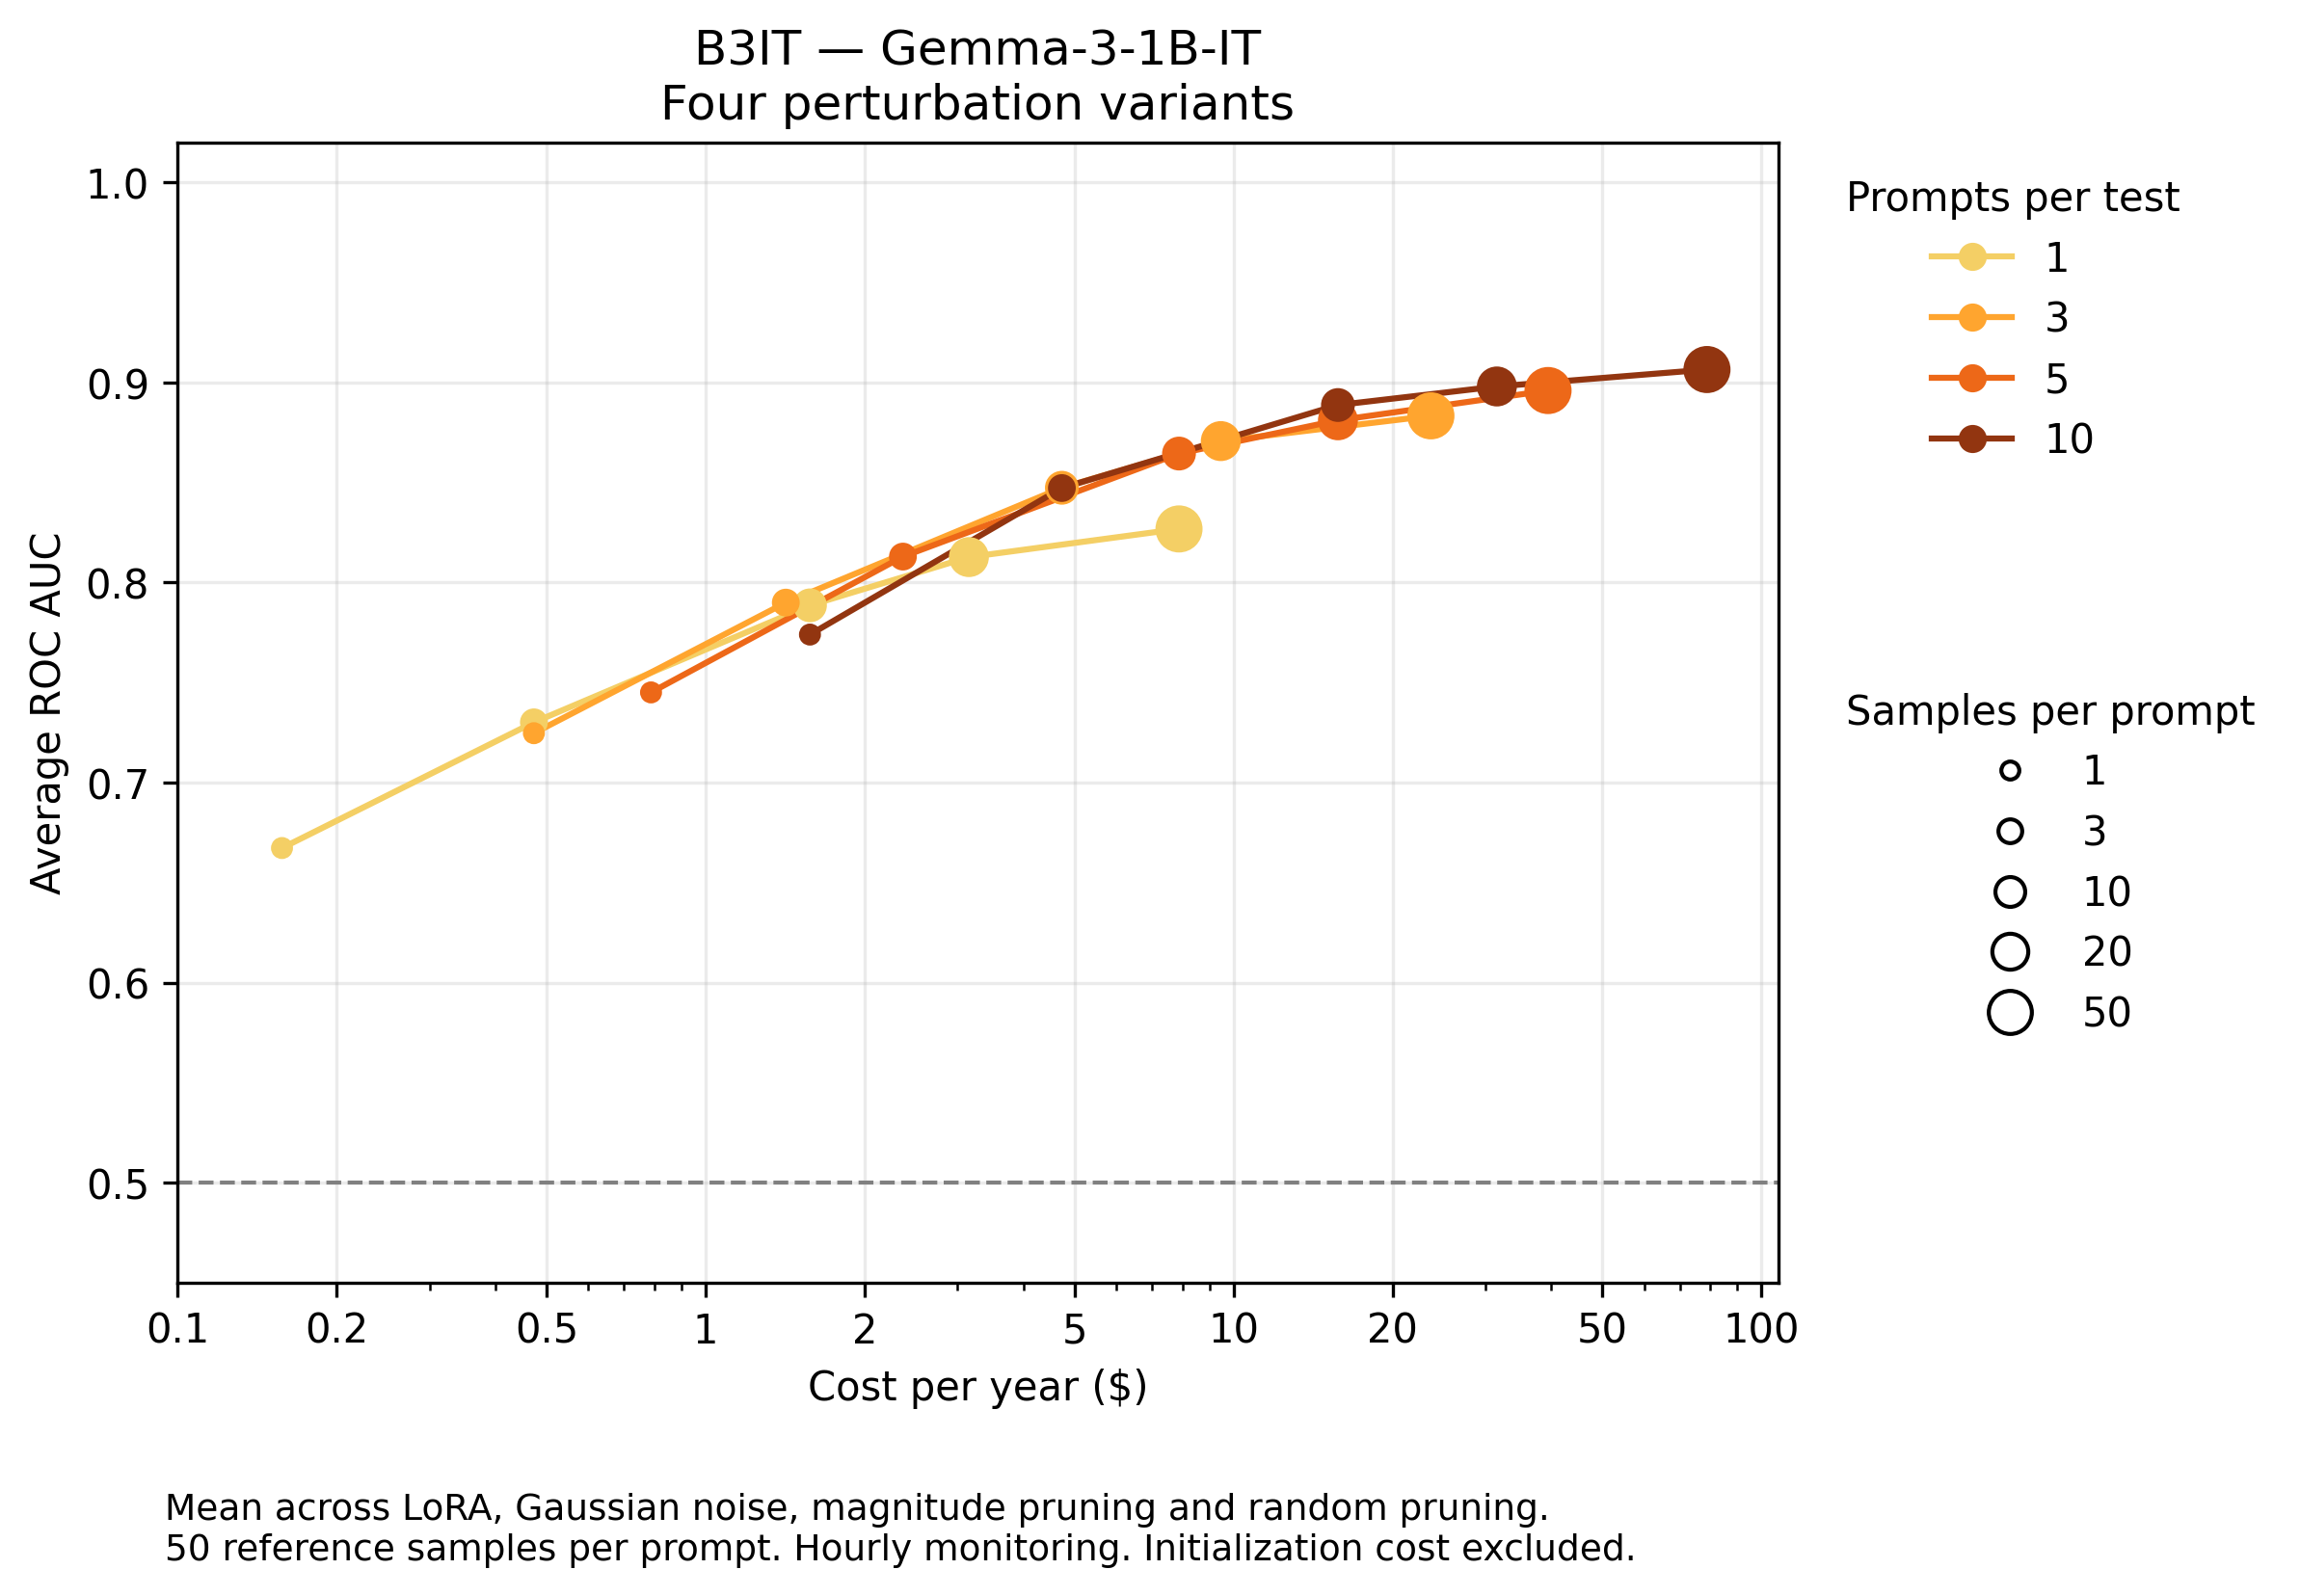

In [13]:
import subprocess
from IPython.display import Image, display
import os
plot_code = r'''
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd

from track_llm_apis.sampling.common import DataSource, load_single_variant_results
from track_llm_apis.sampling.analyze_param_sweeps import compute_auc_from_stats
from track_llm_apis.util import compute_yearly_cost

root = Path(sys.argv[1])
output = root / "results/figure1"
output.mkdir(parents=True, exist_ok=True)

results = load_single_variant_results([root / "results/figure1_merged"], DataSource.BI)
rows = []
for result in results:
    p = int(result.params["n_prompts"])
    s = int(result.params["detection_samples"])
    auc = compute_auc_from_stats(result.h0_stats.stats, result.h1_stats.stats, sampling=False)
    cost = compute_yearly_cost(
        input_tokens_per_sample=result.h1_stats.input_token_avg / s,
        output_tokens_per_sample=result.h1_stats.output_token_avg / s,
        n_samples=s,
    )
    rows.append({
        "model": result.model_name,
        "variant": result.variant,
        "n_prompts": p,
        "samples_per_prompt": s,
        "roc_auc": float(auc),
        "yearly_cost_usd": float(cost),
    })

table = pd.DataFrame(rows)
keys = ["n_prompts", "samples_per_prompt"]
prompt_counts = [1, 3, 5, 10]
sample_counts = [1, 3, 10, 20, 50]
expected = {(p, s) for p in prompt_counts for s in sample_counts}

assert len(table) == 80 and set(table["model"]) == {"google/gemma-3-1b-it"}
assert table["roc_auc"].between(0, 1).all()
assert np.isfinite(table["yearly_cost_usd"]).all() and (table["yearly_cost_usd"] > 0).all()
groups = table.groupby(keys, sort=True)
assert set(groups.groups) == expected
assert table["variant"].nunique() == 4 and groups["variant"].nunique().eq(4).all()
for _, group in groups:
    costs = group["yearly_cost_usd"]
    assert np.allclose(costs, costs.iloc[0]), "Annual costs differ within a setting."

summary = groups.agg(
    mean_roc_auc=("roc_auc", "mean"),
    yearly_cost_usd=("yearly_cost_usd", "first"),
    number_of_variants=("variant", "nunique"),
).reset_index()

table.sort_values(keys + ["variant"]).to_csv(output / "figure1_per_variant.csv", index=False)
summary.to_csv(output / "figure1_summary.csv", index=False)

colors = {1: "#f4cf65", 3: "#ffa52f", 5: "#ed6818", 10: "#923510"}
sizes = {1: 20, 3: 35, 10: 55, 20: 80, 50: 115}
fig, ax = plt.subplots(figsize=(9, 5.8))
fig.subplots_adjust(right=0.74, bottom=0.20)

for p, color in colors.items():
    points = summary[summary["n_prompts"] == p].sort_values("samples_per_prompt")
    x = points["yearly_cost_usd"]
    y = points["mean_roc_auc"]
    ax.plot(x, y, color=color, linewidth=1.5, marker=None)
    ax.scatter(x, y, s=points["samples_per_prompt"].map(sizes), color=color, zorder=3)

ticks = [0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100]
ax.set_xscale("log")
ax.set_xticks(ticks, labels=[str(t) for t in ticks])
ax.set_ylim(min(0.45, summary["mean_roc_auc"].min() - 0.02), 1.02)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.set_xlabel("Cost per year ($)")
ax.set_ylabel("Average ROC AUC")
ax.set_title("B3IT — Gemma-3-1B-IT\nFour perturbation variants")
ax.grid(True, which="major", alpha=0.25)

first = ax.legend(
    handles=[Line2D([], [], color=c, marker="o", label=str(p)) for p, c in colors.items()],
    title="Prompts per test", loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False,
)
ax.add_artist(first)
ax.legend(
    handles=[
        Line2D([], [], linestyle="", marker="o", markerfacecolor="none",
               markeredgecolor="black", markersize=np.sqrt(size), label=str(s))
        for s, size in sizes.items()
    ],
    title="Samples per prompt", loc="upper left", bbox_to_anchor=(1.02, 0.55),
    frameon=False,
)
fig.text(
    0.12, 0.035,
    "Mean across LoRA, Gaussian noise, magnitude pruning and random pruning.\n"
    "50 reference samples per prompt. Hourly monitoring. Initialization cost excluded.",
    fontsize=9,
)
for extension in ("png", "pdf"):
    fig.savefig(output / f"figure1_gemma.{extension}", dpi=300, bbox_inches="tight")
plt.close(fig)

print(summary.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"Step 23 passed: Gemma Figure 1 and both CSV tables saved in {output}")
'''

script = ROOT / "code" / "plot_figure1_gemma.py"
script.write_text(plot_code)
subprocess.run(
    [PYTHON, "-u", str(script), str(ROOT)],
    cwd=PROJECT_DIR,
    env={**os.environ, "MPLBACKEND": "Agg"},
    check=True,
)
display(Image(filename=str(ROOT / "results/figure1/figure1_gemma.png")))

In [14]:
import csv
from pathlib import Path

results = Path("/workspace/B3IT_Figure1_Gemma1B/results")

for model, folder in [("Qwen", "qwen_import"), ("Gemma", "figure1")]:
    for filename, expected_rows in [
        ("figure1_summary.csv", 20),
        ("figure1_per_variant.csv", 80),
    ]:
        path = results / folder / filename
        with path.open(encoding="utf-8-sig", newline="") as file:
            reader = csv.DictReader(file)
            columns = reader.fieldnames
            rows = list(reader)

        print(f"\n{model} | {filename} | {len(rows)} rows")
        print("Columns:", columns)
        assert len(rows) == expected_rows, f"Expected {expected_rows} rows in {path}"
        print("First row:", rows[0])

print("\nStep 24 passed.")


Qwen | figure1_summary.csv | 20 rows
Columns: ['n_prompts', 'samples_per_prompt', 'mean_roc_auc', 'yearly_cost_usd', 'number_of_variants']
First row: {'n_prompts': '1', 'samples_per_prompt': '1', 'mean_roc_auc': '0.7635271875', 'yearly_cost_usd': '0.13140000000000002', 'number_of_variants': '4'}

Qwen | figure1_per_variant.csv | 80 rows
Columns: ['model', 'variant', 'n_prompts', 'samples_per_prompt', 'roc_auc', 'yearly_cost_usd']
First row: {'model': 'Qwen/Qwen2.5-0.5B-Instruct', 'variant': '{"type":"finetune","lr":1e-06,"n_samples":128,"lora":true}', 'n_prompts': '1', 'samples_per_prompt': '1', 'roc_auc': '0.5290742500000001', 'yearly_cost_usd': '0.13140000000000002'}

Gemma | figure1_summary.csv | 20 rows
Columns: ['n_prompts', 'samples_per_prompt', 'mean_roc_auc', 'yearly_cost_usd', 'number_of_variants']
First row: {'n_prompts': '1', 'samples_per_prompt': '1', 'mean_roc_auc': '0.6672622500000001', 'yearly_cost_usd': '0.15768000000000001', 'number_of_variants': '4'}

Gemma | figure1

1 prompt × 1 sample: AUC 0.715395, annual cost $0.14454
Step 25 passed: 20 matched settings. CSV, PNG and PDF saved in /workspace/B3IT_Figure1_Gemma1B/results/figure1_qwen_gemma


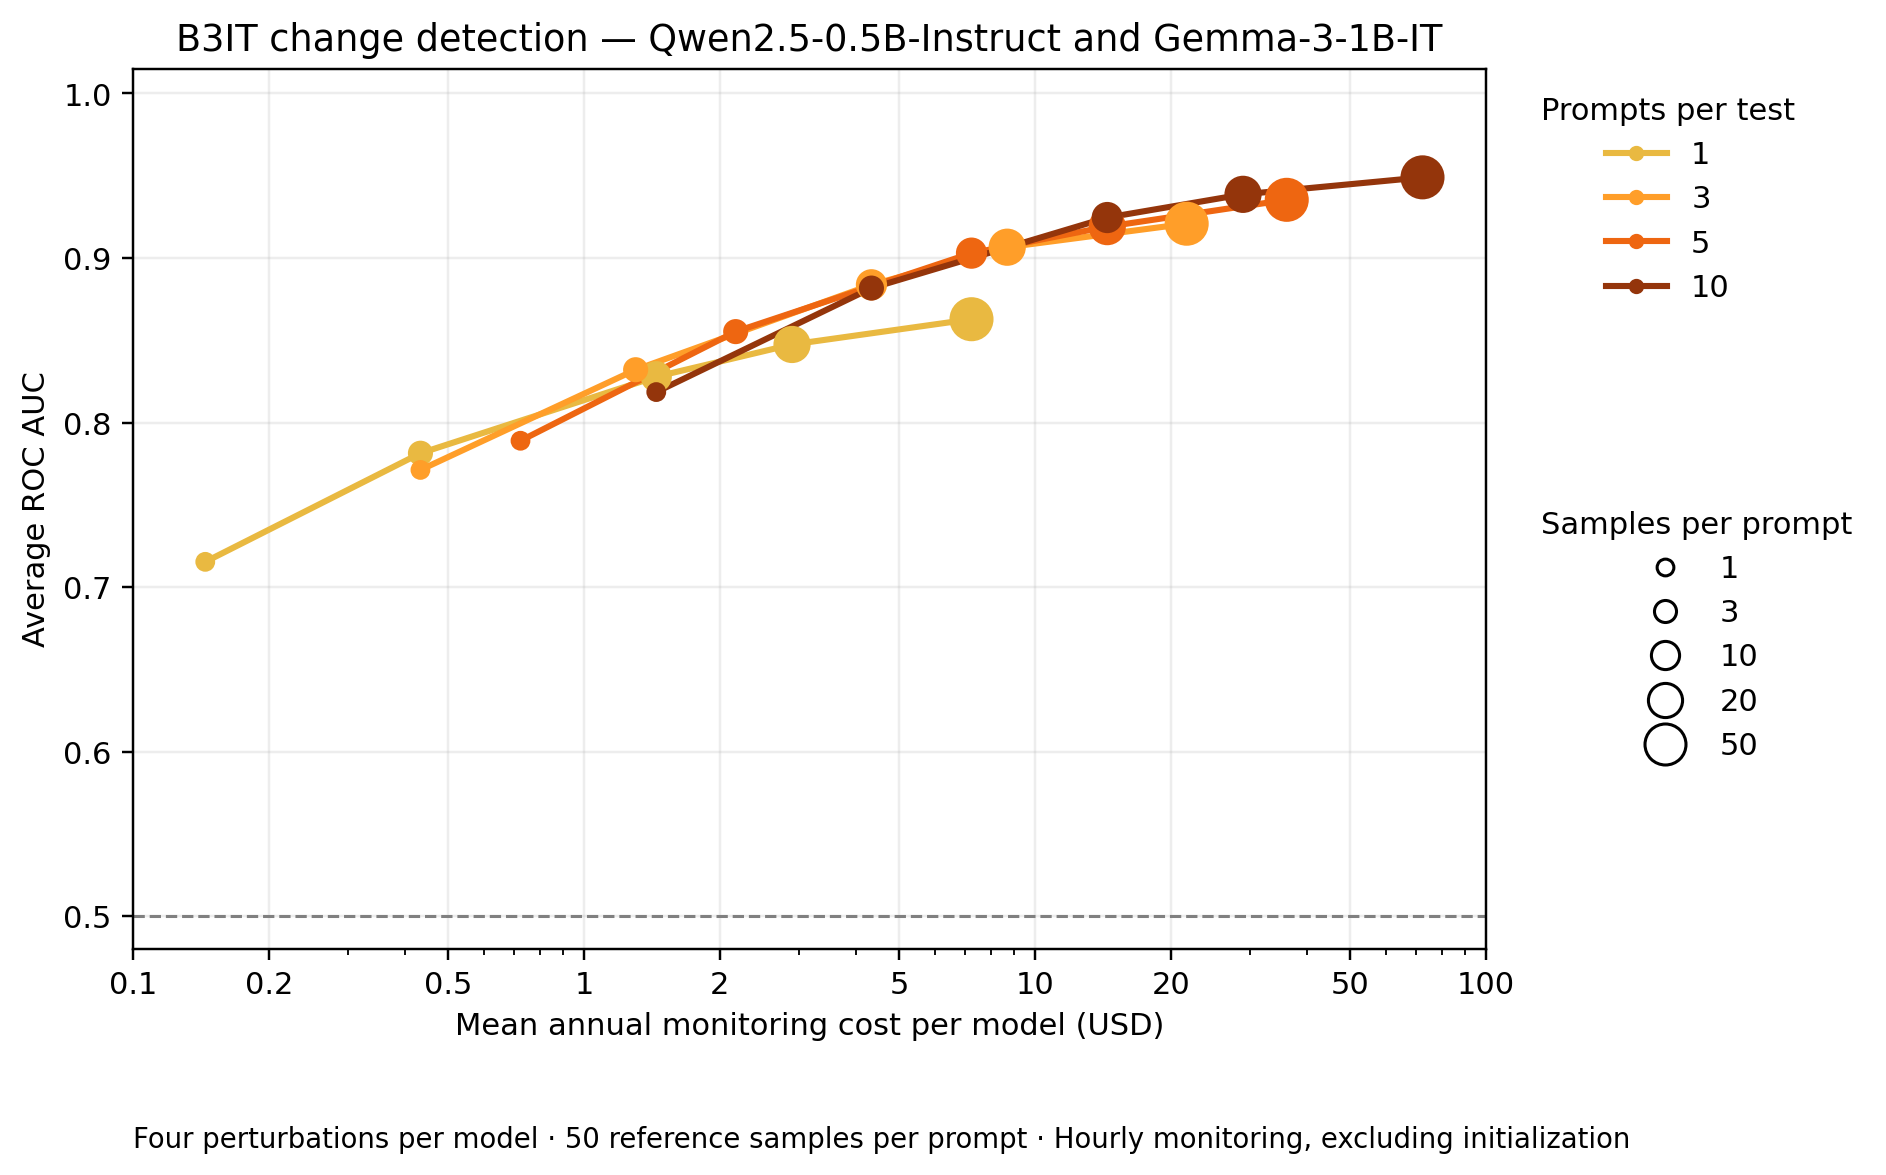

In [15]:
import os
import subprocess
from pathlib import Path
from IPython.display import Image, display

root = Path("/workspace/B3IT_Figure1_Gemma1B")
python = root / "repo/track-llm-apis/.venv/bin/python"
script = root / "code/plot_figure1_qwen_gemma.py"

script.write_text(r'''
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.lines import Line2D

results = Path(sys.argv[1]) / "results"
out = results / "figure1_qwen_gemma"
out.mkdir(exist_ok=True)

keys = ["n_prompts", "samples_per_prompt"]
prompt_counts = [1, 3, 5, 10]
sample_counts = [1, 3, 10, 20, 50]
expected = {(p, s) for p in prompt_counts for s in sample_counts}

def read_summary(folder, model):
    df = pd.read_csv(results / folder / "figure1_summary.csv")
    assert len(df) == 20 and set(zip(df.n_prompts, df.samples_per_prompt)) == expected, (
        f"{model}: expected exactly one row for each of the 20 settings"
    )
    assert df.number_of_variants.eq(4).all(), f"{model}: expected four variants"
    assert df.mean_roc_auc.between(0, 1).all(), f"{model}: invalid ROC AUC"
    assert df.yearly_cost_usd.between(0, float("inf"), inclusive="neither").all(), (
        f"{model}: invalid annual cost"
    )
    return df[keys + ["mean_roc_auc", "yearly_cost_usd"]].rename(columns={
        "mean_roc_auc": f"{model}_auc",
        "yearly_cost_usd": f"{model}_cost_usd",
    })

combined = read_summary("qwen_import", "qwen").merge(
    read_summary("figure1", "gemma"), on=keys, validate="one_to_one"
).sort_values(keys)

combined["mean_roc_auc"] = (combined.qwen_auc + combined.gemma_auc) / 2
combined["mean_yearly_cost_usd"] = (combined.qwen_cost_usd + combined.gemma_cost_usd) / 2
combined.to_csv(out / "figure1_summary.csv", index=False)

colors = ["#e9b941", "#ff9e29", "#ee6611", "#94350b"]
areas = {1: 30, 3: 52, 10: 85, 20: 125, 50: 180}
fig, ax = plt.subplots(figsize=(10, 5.8))
fig.subplots_adjust(right=0.74, bottom=0.19)

for count, color in zip(prompt_counts, colors):
    rows = combined[combined.n_prompts == count]
    x, y = rows.mean_yearly_cost_usd, rows.mean_roc_auc
    ax.plot(x, y, color=color, linewidth=2, marker="o", markersize=4, label=str(count))
    ax.scatter(x, y, s=rows.samples_per_prompt.map(areas), color=color, zorder=3)

ax.set_xscale("log")
ticks = [0.1, 0.2, 0.5, 1, 2, 5, 10, 20, 50, 100]
ax.set_xticks(ticks, [str(t) for t in ticks])
ax.set_ylim(0.48, 1.015)
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1)
ax.grid(alpha=0.22)
ax.set_axisbelow(True)
ax.set_title("B3IT change detection — Qwen2.5-0.5B-Instruct and Gemma-3-1B-IT")
ax.set_xlabel("Mean annual monitoring cost per model (USD)")
ax.set_ylabel("Average ROC AUC")

prompt_legend = ax.legend(title="Prompts per test", loc="upper left",
                          bbox_to_anchor=(1.02, 1), frameon=False)
ax.add_artist(prompt_legend)
markers = [
    Line2D([], [], linestyle="", marker="o", markersize=areas[s] ** 0.5,
           markerfacecolor="white", markeredgecolor="black", label=str(s))
    for s in sample_counts
]
ax.legend(handles=markers, title="Samples per prompt", loc="upper left",
          bbox_to_anchor=(1.02, 0.53), frameon=False)

fig.text(0.125, 0.035,
         "Four perturbations per model · 50 reference samples per prompt · "
         "Hourly monitoring, excluding initialization", fontsize=9)
for ext in ["png", "pdf"]:
    fig.savefig(out / f"figure1_qwen_gemma.{ext}", dpi=220, bbox_inches="tight")
plt.close(fig)

first = combined.iloc[0]
print(f"1 prompt × 1 sample: AUC {first.mean_roc_auc:.6f}, annual cost ${first.mean_yearly_cost_usd:.5f}")
print(f"Step 25 passed: 20 matched settings. CSV, PNG and PDF saved in {out}")
''', encoding="utf-8")

subprocess.run(
    [str(python), str(script), str(root)],
    env={**os.environ, "MPLBACKEND": "Agg"},
    check=True,
)
display(Image(filename=str(root / "results/figure1_qwen_gemma/figure1_qwen_gemma.png")))

In [ ]:
import csv
import shutil
from pathlib import Path

source = Path("/workspace/B3IT_Figure1_Phi4Mini/results/figure1")
destination = Path("/workspace/B3IT_Figure1_Gemma1B/results/phi_import")

assert source.is_dir(), (
    f"Phi folder is unavailable on this pod: {source}\n"
    "Download both CSVs from the Phi pod and upload them into results/phi_import."
)
destination.mkdir(parents=True, exist_ok=True)

for filename, expected_rows in [
    ("figure1_summary.csv", 20),
    ("figure1_per_variant.csv", 80),
]:
    path = source / filename
    with path.open(encoding="utf-8-sig", newline="") as file:
        reader = csv.DictReader(file)
        rows = list(reader)
        columns = reader.fieldnames

    assert len(rows) == expected_rows, (
        f"{filename}: expected {expected_rows} rows, found {len(rows)}"
    )
    shutil.copy2(path, destination / filename)

    print(f"\n{filename}: {len(rows)} rows")
    print("Columns:", columns)
    print("First row:", rows[0])

print("\nPhi results copied and verified:", destination)